In [ ]:
from pathlib import Path
from zipfile import ZipFile

from google.colab import drive
drive.mount("/content/drive")

cotton_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
if not cotton_dir.is_dir():
    raise FileNotFoundError(f"Cotton folder not found: {cotton_dir}")

zip_files = sorted(cotton_dir.glob("*.zip"))
print(f"ZIP files found in {cotton_dir}:")
for path in zip_files:
    print(f"  {path.name} ({path.stat().st_size / (1024**3):.2f} GB)")

if len(zip_files) == 0:
    raise FileNotFoundError("No .zip file found directly inside the cotton folder.")
if len(zip_files) > 1:
    raise RuntimeError("More than one ZIP found. Choose the dataset ZIP before extracting.")

zip_path = zip_files[0]
extract_dir = cotton_dir / "dataset"
extract_dir.mkdir(parents=True, exist_ok=True)

# Check archive paths before extracting to prevent files escaping the dataset folder.
with ZipFile(zip_path) as archive:
    root = extract_dir.resolve()
    unsafe = [
        name for name in archive.namelist()
        if not (root / name).resolve().is_relative_to(root)
    ]
    if unsafe:
        raise RuntimeError(f"Unsafe paths found in ZIP; nothing extracted. Examples: {unsafe[:5]}")

    archive.extractall(extract_dir)

print(f"\nExtracted: {zip_path.name}")
print(f"Dataset folder: {extract_dir}")
print("Top-level contents:")
for path in sorted(extract_dir.iterdir()):
    print(f"  {'[DIR]' if path.is_dir() else '[FILE]'} {path.name}")

Mounted at /content/drive
ZIP files found in /content/drive/MyDrive/final_year_project/cotton:
  SAR-CLD-2024 A Comprehensive Dataset for Cotton Leaf Disease Detection.zip (0.21 GB)

Extracted: SAR-CLD-2024 A Comprehensive Dataset for Cotton Leaf Disease Detection.zip
Dataset folder: /content/drive/MyDrive/final_year_project/cotton/dataset
Top-level contents:
  [DIR] SAR-CLD-2024 A Comprehensive Dataset for Cotton Leaf Disease Detection


In [ ]:
from pathlib import Path
from collections import Counter

dataset_root = Path(
    "/content/drive/MyDrive/final_year_project/cotton/dataset/"
    "SAR-CLD-2024 A Comprehensive Dataset for Cotton Leaf Disease Detection"
)

if not dataset_root.exists():
    raise FileNotFoundError(f"Dataset folder not found: {dataset_root}")

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
all_files = [p for p in dataset_root.rglob("*") if p.is_file()]
images = [p for p in all_files if p.suffix.lower() in image_extensions]

print(f"All files: {len(all_files):,}")
print(f"Image files: {len(images):,}")
print("\nFolder tree (up to 3 levels):")

for path in sorted(dataset_root.rglob("*")):
    relative = path.relative_to(dataset_root)
    if len(relative.parts) <= 3:
        indent = "  " * (len(relative.parts) - 1)
        print(f"{indent}{'[DIR]' if path.is_dir() else '[FILE]'} {path.name}")

print("\nImage counts by immediate parent folder:")
counts = Counter(p.parent.name for p in images)
for class_name, count in sorted(counts.items()):
    print(f"  {class_name}: {count:,}")

All files: 1,743
Image files: 1,743

Folder tree (up to 3 levels):
[DIR] Bacterial Blight
  [FILE] BBC00001.jpg
  [FILE] BBC00002.jpg
  [FILE] BBC00003.jpg
  [FILE] BBC00004.jpg
  [FILE] BBC00005.jpg
  [FILE] BBC00006.jpg
  [FILE] BBC00007.jpg
  [FILE] BBC00008.jpg
  [FILE] BBC00009.jpg
  [FILE] BBC00010.jpg
  [FILE] BBC00011.jpg
  [FILE] BBC00012.jpg
  [FILE] BBC00013.jpg
  [FILE] BBC00014.jpg
  [FILE] BBC00015.jpg
  [FILE] BBC00016.jpg
  [FILE] BBC00017.jpg
  [FILE] BBC00018.jpg
  [FILE] BBC00019.jpg
  [FILE] BBC00020.jpg
  [FILE] BBC00021.jpg
  [FILE] BBC00022.jpg
  [FILE] BBC00023.jpg
  [FILE] BBC00024.jpg
  [FILE] BBC00025.jpg
  [FILE] BBC00026.jpg
  [FILE] BBC00027.jpg
  [FILE] BBC00028.jpg
  [FILE] BBC00029.jpg
  [FILE] BBC00030.jpg
  [FILE] BBC00031.jpg
  [FILE] BBC00032.jpg
  [FILE] BBC00033.jpg
  [FILE] BBC00034.jpg
  [FILE] BBC00035.jpg
  [FILE] BBC00036.jpg
  [FILE] BBC00037.jpg
  [FILE] BBC00038.jpg
  [FILE] BBC00039.jpg
  [FILE] BBC00040.jpg
  [FILE] BBC00041.jpg
  [FILE]

In [ ]:
from pathlib import Path
from collections import Counter, defaultdict
from PIL import Image, UnidentifiedImageError
import csv

dataset_root = Path(
    "/content/drive/MyDrive/final_year_project/cotton/dataset/"
    "SAR-CLD-2024 A Comprehensive Dataset for Cotton Leaf Disease Detection"
)
project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

images = sorted(p for p in dataset_root.rglob("*")
                if p.is_file() and p.suffix.lower() in image_extensions)

class_counts = Counter()
size_counts = Counter()
unreadable = []
rows = []

for path in images:
    class_name = path.parent.name
    class_counts[class_name] += 1

    try:
        with Image.open(path) as im:
            im.verify()
        with Image.open(path) as im:
            width, height = im.size
            fmt = im.format
        size_counts[(width, height)] += 1
        rows.append([str(path.relative_to(dataset_root)), class_name,
                     width, height, fmt, "ok"])
    except Exception as e:
        unreadable.append((str(path), repr(e)))
        rows.append([str(path.relative_to(dataset_root)), class_name,
                     "", "", "", f"error: {type(e).__name__}"])

print(f"Images found: {len(images):,}")
print(f"Readable: {len(images) - len(unreadable):,}")
print(f"Unreadable: {len(unreadable):,}")

print("\nCounts by class folder:")
for name, count in sorted(class_counts.items()):
    print(f"  {name}: {count:,}")

print("\nMost common image sizes (width × height):")
for (width, height), count in size_counts.most_common(20):
    print(f"  {width} × {height}: {count:,}")

if unreadable:
    print("\nUnreadable files:")
    for path, error in unreadable[:50]:
        print(f"  {path} — {error}")
    if len(unreadable) > 50:
        print(f"  ... and {len(unreadable) - 50:,} more")

report_path = project_dir / "inventory_report.csv"
with report_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["relative_path", "class_folder", "width", "height", "format", "status"])
    writer.writerows(rows)

print(f"\nDetailed inventory saved to: {report_path}")

Images found: 1,743
Readable: 1,743
Unreadable: 0

Counts by class folder:
  Bacterial Blight: 250
  Curl Virus: 431
  Healthy Leaf: 259
  Leaf Hopper Jassids: 225
  Leaf Redding: 578

Most common image sizes (width × height):
  800 × 800: 1,627
  694 × 694: 37
  687 × 611: 6
  800 × 640: 5
  685 × 674: 3
  691 × 613: 3
  357 × 293: 3
  501 × 406: 3
  623 × 678: 3
  910 × 605: 3
  1080 × 865: 3
  1280 × 850: 3
  691 × 618: 3
  691 × 602: 3
  690 × 592: 3
  691 × 616: 3
  691 × 615: 3
  687 × 614: 3
  690 × 611: 3
  691 × 424: 3

Detailed inventory saved to: /content/drive/MyDrive/final_year_project/cotton/inventory_report.csv


In [ ]:
from pathlib import Path
from collections import defaultdict
import hashlib
import csv

dataset_root = Path(
    "/content/drive/MyDrive/final_year_project/cotton/dataset/"
    "SAR-CLD-2024 A Comprehensive Dataset for Cotton Leaf Disease Detection"
)
project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

images = sorted(
    p for p in dataset_root.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
)

def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with path.open("rb") as f:
        while chunk := f.read(chunk_size):
            digest.update(chunk)
    return digest.hexdigest()

groups = defaultdict(list)
for path in images:
    groups[sha256_file(path)].append(path)

duplicate_groups = {h: paths for h, paths in groups.items() if len(paths) > 1}
conflicts = []
duplicate_rows = []

for group_id, (digest, paths) in enumerate(sorted(duplicate_groups.items()), start=1):
    labels = sorted({p.parent.name for p in paths})
    conflict = len(labels) > 1
    if conflict:
        conflicts.append((group_id, digest, labels, paths))

    for path in paths:
        duplicate_rows.append([
            group_id,
            digest,
            path.parent.name,
            str(path.relative_to(dataset_root)),
            "conflicting_labels" if conflict else "same_label_duplicate",
        ])

manifest_path = project_dir / "exact_duplicate_manifest.csv"
with manifest_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["duplicate_group", "sha256", "label", "relative_path", "group_status"])
    writer.writerows(duplicate_rows)

conflict_path = project_dir / "conflicting_label_duplicates.csv"
with conflict_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["duplicate_group", "sha256", "labels", "relative_paths"])
    for group_id, digest, labels, paths in conflicts:
        writer.writerow([
            group_id,
            digest,
            " | ".join(labels),
            " | ".join(str(p.relative_to(dataset_root)) for p in paths),
        ])

print(f"Images hashed: {len(images):,}")
print(f"Exact duplicate groups: {len(duplicate_groups):,}")
print(f"Files belonging to duplicate groups: {len(duplicate_rows):,}")
print(f"Conflicting-label duplicate groups: {len(conflicts):,}")
print(f"\nManifest: {manifest_path}")
print(f"Conflict report: {conflict_path}")

if conflicts:
    print("\nConflicting-label groups:")
    for group_id, digest, labels, paths in conflicts:
        print(f"\nGroup {group_id}: labels={labels}")
        for path in paths:
            print(f"  {path.relative_to(dataset_root)}")

Images hashed: 1,743
Exact duplicate groups: 41
Files belonging to duplicate groups: 82
Conflicting-label duplicate groups: 5

Manifest: /content/drive/MyDrive/final_year_project/cotton/exact_duplicate_manifest.csv
Conflict report: /content/drive/MyDrive/final_year_project/cotton/conflicting_label_duplicates.csv

Conflicting-label groups:

Group 4: labels=['Curl Virus', 'Healthy Leaf']
  Curl Virus/CV00022.jpg
  Healthy Leaf/HL00104.jpg

Group 16: labels=['Curl Virus', 'Healthy Leaf']
  Curl Virus/CV00019.jpg
  Healthy Leaf/HL00101.jpg

Group 20: labels=['Curl Virus', 'Healthy Leaf']
  Curl Virus/CV00021.jpg
  Healthy Leaf/HL00103.jpg

Group 21: labels=['Curl Virus', 'Healthy Leaf']
  Curl Virus/CV00018.jpg
  Healthy Leaf/HL00085.jpg

Group 36: labels=['Curl Virus', 'Healthy Leaf']
  Curl Virus/CV00020.jpg
  Healthy Leaf/HL00102.jpg


In [ ]:
from pathlib import Path
from collections import defaultdict
import hashlib
import csv
import shutil

dataset_root = Path(
    "/content/drive/MyDrive/final_year_project/cotton/dataset/"
    "SAR-CLD-2024 A Comprehensive Dataset for Cotton Leaf Disease Detection"
)
project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
review_dir = project_dir / "exact_duplicate_review"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
images = sorted(
    p for p in dataset_root.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
)

def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with path.open("rb") as f:
        while chunk := f.read(chunk_size):
            digest.update(chunk)
    return digest.hexdigest()

# Group identical file contents.
groups = defaultdict(list)
for path in images:
    groups[sha256_file(path)].append(path)

# For each group, determine whether it has conflicting labels.
moves = []
for digest, paths in groups.items():
    if len(paths) <= 1:
        continue

    labels = {p.parent.name for p in paths}
    if len(labels) > 1:
        # Conflicting labels: move every copy out of the dataset.
        to_move = paths
        reason = "conflicting_label_all_copies_excluded"
    else:
        # Same label: keep the first path, move the extra copies.
        to_move = sorted(paths)[1:]
        reason = "same_label_extra_copy"

    for path in to_move:
        moves.append((path, digest, reason))

# Show the planned changes before applying them.
print(f"Images currently in dataset: {len(images):,}")
print(f"Files to move: {len(moves):,}")
for path, digest, reason in moves:
    print(f"  {reason}: {path.relative_to(dataset_root)}")

# Move files into a parallel review folder, preserving their class subfolders.
review_dir.mkdir(parents=True, exist_ok=True)
log_path = project_dir / "exact_duplicate_cleanup_log.csv"

with log_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["sha256", "reason", "original_path", "review_copy_path"])

    for source, digest, reason in moves:
        relative = source.relative_to(dataset_root)
        destination = review_dir / relative
        destination.parent.mkdir(parents=True, exist_ok=True)

        if destination.exists():
            raise FileExistsError(f"Refusing to overwrite existing review file: {destination}")

        shutil.move(str(source), str(destination))
        writer.writerow([digest, reason, str(source), str(destination)])

remaining = [
    p for p in dataset_root.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print(f"\nImages remaining in dataset: {len(remaining):,}")
print(f"Moved files are preserved in: {review_dir}")
print(f"Cleanup log: {log_path}")

Images currently in dataset: 1,743
Files to move: 46
  conflicting_label_all_copies_excluded: Curl Virus/CV00018.jpg
  conflicting_label_all_copies_excluded: Healthy Leaf/HL00085.jpg
  conflicting_label_all_copies_excluded: Curl Virus/CV00019.jpg
  conflicting_label_all_copies_excluded: Healthy Leaf/HL00101.jpg
  conflicting_label_all_copies_excluded: Curl Virus/CV00020.jpg
  conflicting_label_all_copies_excluded: Healthy Leaf/HL00102.jpg
  conflicting_label_all_copies_excluded: Curl Virus/CV00021.jpg
  conflicting_label_all_copies_excluded: Healthy Leaf/HL00103.jpg
  conflicting_label_all_copies_excluded: Curl Virus/CV00022.jpg
  conflicting_label_all_copies_excluded: Healthy Leaf/HL00104.jpg
  same_label_extra_copy: Healthy Leaf/pil_color_1.jpg
  same_label_extra_copy: Healthy Leaf/pil_color_10.jpg
  same_label_extra_copy: Healthy Leaf/pil_color_11.jpg
  same_label_extra_copy: Healthy Leaf/pil_color_13.jpg
  same_label_extra_copy: Healthy Leaf/pil_color_14.jpg
  same_label_extra_copy

In [ ]:
from pathlib import Path
from PIL import Image, ImageOps, ImageDraw
from collections import defaultdict
import imagehash
import csv
import itertools
import math

dataset_root = Path(
    "/content/drive/MyDrive/final_year_project/cotton/dataset/"
    "SAR-CLD-2024 A Comprehensive Dataset for Cotton Leaf Disease Detection"
)
project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

images = sorted(
    p for p in dataset_root.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
)

# Hash the cleaned dataset images.
hashes = {}
for path in images:
    try:
        with Image.open(path) as im:
            hashes[path] = imagehash.phash(
                ImageOps.exif_transpose(im).convert("RGB")
            )
    except Exception as e:
        print(f"Skipping unreadable file: {path} ({e})")

# Find candidate pairs. Review these visually; no files are removed.
threshold = 8
candidates = []
paths = list(hashes)

for i, path_a in enumerate(paths):
    for path_b in paths[i + 1:]:
        distance = hashes[path_a] - hashes[path_b]
        if distance <= threshold:
            candidates.append((distance, path_a, path_b))

candidates.sort(key=lambda row: (row[0], str(row[1]), str(row[2])))

pairs_csv = project_dir / "near_duplicate_candidates.csv"
with pairs_csv.open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["pair_id", "phash_distance", "label_a", "path_a", "label_b", "path_b"])
    for pair_id, (distance, path_a, path_b) in enumerate(candidates, start=1):
        writer.writerow([
            pair_id, distance, path_a.parent.name,
            str(path_a.relative_to(dataset_root)),
            path_b.parent.name,
            str(path_b.relative_to(dataset_root)),
        ])

thumb_w, thumb_h, label_h = 220, 220, 64
cell_w, cell_h = 2 * thumb_w, thumb_h + label_h
cols = 2
rows = max(1, math.ceil(len(candidates) / cols))
sheet = Image.new("RGB", (cols * cell_w, rows * cell_h), "white")
draw = ImageDraw.Draw(sheet)

for idx, (distance, path_a, path_b) in enumerate(candidates):
    x, y = (idx % cols) * cell_w, (idx // cols) * cell_h

    for offset, path in [(0, path_a), (thumb_w, path_b)]:
        with Image.open(path) as im:
            im = ImageOps.exif_transpose(im).convert("RGB")
            im.thumbnail((thumb_w, thumb_h))
            tile = Image.new("RGB", (thumb_w, thumb_h), "white")
            tile.paste(im, ((thumb_w - im.width) // 2, (thumb_h - im.height) // 2))
            sheet.paste(tile, (x + offset, y))

    draw.text(
        (x, y + thumb_h + 3),
        f"Pair {idx + 1} | distance {distance}\n"
        f"A: {path_a.parent.name}/{path_a.name}\n"
        f"B: {path_b.parent.name}/{path_b.name}",
        fill="black",
    )

sheet_path = project_dir / "near_duplicate_contact_sheet.jpg"
sheet.save(sheet_path, quality=90)

print(f"Images hashed: {len(hashes):,}")
print(f"Candidate pairs (pHash distance ≤ {threshold}): {len(candidates):,}")
print(f"Pair list: {pairs_csv}")
print(f"Contact sheet: {sheet_path}")
display(sheet)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
from pathlib import Path
from collections import defaultdict
import csv
import shutil

dataset_root = Path(
    "/content/drive/MyDrive/final_year_project/cotton/dataset/"
    "SAR-CLD-2024 A Comprehensive Dataset for Cotton Leaf Disease Detection"
).resolve()
project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
pairs_csv = project_dir / "near_duplicate_candidates.csv"
review_dir = project_dir / "near_duplicate_review"

if not pairs_csv.exists():
    raise FileNotFoundError(f"Candidate-pair CSV not found: {pairs_csv}")

# Build connected groups from the reviewed candidate pairs.
parent = {}

def find(x):
    parent.setdefault(x, x)
    if parent[x] != x:
        parent[x] = find(parent[x])
    return parent[x]

def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

with pairs_csv.open(newline="", encoding="utf-8") as f:
    pair_rows = list(csv.DictReader(f))

for row in pair_rows:
    a = (dataset_root / row["path_a"]).resolve()
    b = (dataset_root / row["path_b"]).resolve()
    if not a.is_relative_to(dataset_root) or not b.is_relative_to(dataset_root):
        raise ValueError("Candidate CSV contains a path outside the dataset.")
    if not a.is_file() or not b.is_file():
        raise FileNotFoundError(f"Candidate image is missing: {a} or {b}")
    union(str(a), str(b))

components = defaultdict(list)
for path_text in parent:
    components[find(path_text)].append(Path(path_text))

# Plan moves: retain one image for same-label groups; exclude every copy
# when identical-looking candidates have conflicting labels.
moves = []
for paths in components.values():
    paths = sorted(paths, key=lambda p: str(p).lower())
    labels = {p.parent.name for p in paths}

    if len(labels) > 1:
        to_move = paths
        reason = "reviewed_duplicate_group_conflicting_labels"
    else:
        to_move = paths[1:]
        reason = "reviewed_duplicate_extra_copy"

    for path in to_move:
        moves.append((path, reason))

print(f"Reviewed candidate pairs: {len(pair_rows):,}")
print(f"Connected duplicate groups: {len(components):,}")
print(f"Files to move: {len(moves):,}")

review_dir.mkdir(parents=True, exist_ok=True)
log_path = project_dir / "near_duplicate_cleanup_log.csv"

with log_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["reason", "original_path", "review_copy_path"])

    for source, reason in moves:
        relative = source.relative_to(dataset_root)
        destination = review_dir / relative
        destination.parent.mkdir(parents=True, exist_ok=True)

        if destination.exists():
            raise FileExistsError(f"Refusing to overwrite: {destination}")

        shutil.move(str(source), str(destination))
        writer.writerow([reason, str(source), str(destination)])

remaining = [
    p for p in dataset_root.rglob("*")
    if p.is_file() and p.suffix.lower() in
    {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
]

print(f"\nImages remaining in dataset: {len(remaining):,}")
print(f"Moved files preserved in: {review_dir}")
print(f"Cleanup log: {log_path}")

Reviewed candidate pairs: 53
Connected duplicate groups: 44
Files to move: 49

Images remaining in dataset: 1,648
Moved files preserved in: /content/drive/MyDrive/final_year_project/cotton/near_duplicate_review
Cleanup log: /content/drive/MyDrive/final_year_project/cotton/near_duplicate_cleanup_log.csv


Processed 250/1,648 images
Processed 500/1,648 images
Processed 750/1,648 images
Processed 1,000/1,648 images
Processed 1,250/1,648 images
Processed 1,500/1,648 images

Images checked: 1,648
Unreadable/skipped: 0
Likely augmentation-family pairs (distance ≤ 6): 11
Full candidate list: /content/drive/MyDrive/final_year_project/cotton/augmentation_family_candidates.csv
Contact sheet preview (11 pairs): /content/drive/MyDrive/final_year_project/cotton/augmentation_family_contact_sheet.jpg


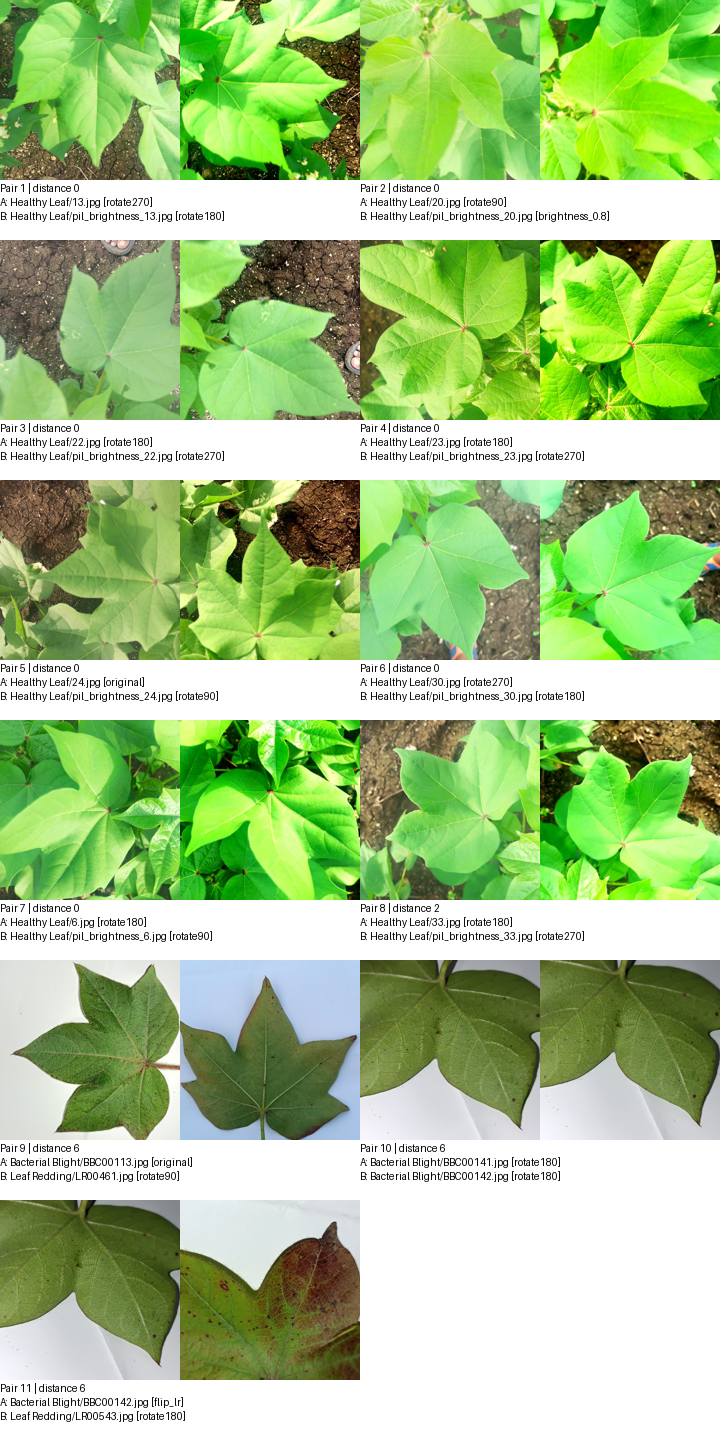

In [ ]:
%pip -q install ImageHash

from pathlib import Path
from PIL import Image, ImageOps, ImageEnhance, ImageDraw
import imagehash
import csv
import math

dataset_root = Path(
    "/content/drive/MyDrive/final_year_project/cotton/dataset/"
    "SAR-CLD-2024 A Comprehensive Dataset for Cotton Leaf Disease Detection"
)
project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

images = sorted(
    p for p in dataset_root.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
)

# For each image, hash several common augmentation variants.
variant_hashes = {}
failed = []

for index, path in enumerate(images, start=1):
    try:
        with Image.open(path) as im:
            base = ImageOps.exif_transpose(im).convert("RGB")

        variants = [
            ("original", base),
            ("rotate90", base.rotate(90, expand=True)),
            ("rotate180", base.rotate(180, expand=True)),
            ("rotate270", base.rotate(270, expand=True)),
            ("flip_lr", ImageOps.mirror(base)),
            ("flip_tb", ImageOps.flip(base)),
            ("brightness_0.8", ImageEnhance.Brightness(base).enhance(0.8)),
            ("brightness_1.2", ImageEnhance.Brightness(base).enhance(1.2)),
            ("contrast_0.8", ImageEnhance.Contrast(base).enhance(0.8)),
            ("contrast_1.2", ImageEnhance.Contrast(base).enhance(1.2)),
        ]
        variant_hashes[path] = [
            (name, imagehash.phash(img))
            for name, img in variants
        ]
    except Exception as e:
        failed.append((path, repr(e)))

    if index % 250 == 0:
        print(f"Processed {index:,}/{len(images):,} images")

# Compare each pair, recording the closest transformation match.
# Hamming distance 0-6 is a conservative review threshold.
threshold = 6
candidates = []
paths = list(variant_hashes)

for i, path_a in enumerate(paths):
    hashes_a = variant_hashes[path_a]
    for path_b in paths[i + 1:]:
        hashes_b = variant_hashes[path_b]

        best_distance = 65
        best_variant_a = None
        best_variant_b = None

        for name_a, hash_a in hashes_a:
            for name_b, hash_b in hashes_b:
                distance = hash_a - hash_b
                if distance < best_distance:
                    best_distance = distance
                    best_variant_a = name_a
                    best_variant_b = name_b

        if best_distance <= threshold:
            candidates.append(
                (best_distance, path_a, path_b, best_variant_a, best_variant_b)
            )

candidates.sort(key=lambda row: (row[0], str(row[1]), str(row[2])))

pairs_csv = project_dir / "augmentation_family_candidates.csv"
with pairs_csv.open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow([
        "pair_id", "phash_distance", "label_a", "path_a",
        "label_b", "path_b", "best_variant_a", "best_variant_b"
    ])
    for pair_id, (distance, path_a, path_b, var_a, var_b) in enumerate(candidates, 1):
        writer.writerow([
            pair_id, distance, path_a.parent.name,
            str(path_a.relative_to(dataset_root)),
            path_b.parent.name,
            str(path_b.relative_to(dataset_root)),
            var_a, var_b
        ])

# Contact sheet preview (first 80 candidates, sorted by hash distance).
preview_count = min(80, len(candidates))
thumb_w, thumb_h, label_h = 180, 180, 60
cell_w, cell_h = thumb_w * 2, thumb_h + label_h
cols = 2
rows = max(1, math.ceil(preview_count / cols))
sheet = Image.new("RGB", (cols * cell_w, rows * cell_h), "white")
draw = ImageDraw.Draw(sheet)

for idx, (distance, path_a, path_b, var_a, var_b) in enumerate(candidates[:preview_count]):
    x, y = (idx % cols) * cell_w, (idx // cols) * cell_h

    for offset, path in [(0, path_a), (thumb_w, path_b)]:
        with Image.open(path) as im:
            im = ImageOps.exif_transpose(im).convert("RGB")
            im.thumbnail((thumb_w, thumb_h))
            tile = Image.new("RGB", (thumb_w, thumb_h), "white")
            tile.paste(im, ((thumb_w - im.width) // 2, (thumb_h - im.height) // 2))
            sheet.paste(tile, (x + offset, y))

    draw.text(
        (x, y + thumb_h + 2),
        f"Pair {idx + 1} | distance {distance}\n"
        f"A: {path_a.parent.name}/{path_a.name} [{var_a}]\n"
        f"B: {path_b.parent.name}/{path_b.name} [{var_b}]",
        fill="black",
    )

sheet_path = project_dir / "augmentation_family_contact_sheet.jpg"
sheet.save(sheet_path, quality=90)

print(f"\nImages checked: {len(variant_hashes):,}")
print(f"Unreadable/skipped: {len(failed):,}")
print(f"Likely augmentation-family pairs (distance ≤ {threshold}): {len(candidates):,}")
print(f"Full candidate list: {pairs_csv}")
print(f"Contact sheet preview ({preview_count} pairs): {sheet_path}")

if failed:
    print("\nSkipped files:")
    for path, error in failed[:20]:
        print(f"  {path}: {error}")

display(sheet)


In [ ]:
from pathlib import Path
from collections import defaultdict, Counter
import csv
import json
import random

dataset_root = Path(
    "/content/drive/MyDrive/final_year_project/cotton/dataset/"
    "SAR-CLD-2024 A Comprehensive Dataset for Cotton Leaf Disease Detection"
).resolve()
project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
images = sorted(
    p for p in dataset_root.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
)
if not images:
    raise FileNotFoundError(f"No images found under {dataset_root}")

# Build duplicate-family groups from reviewed candidate manifests.
parent = {str(p): str(p) for p in images}

def find(x):
    if parent[x] != x:
        parent[x] = find(parent[x])
    return parent[x]

def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

def add_candidate_edges(csv_path, col_a="path_a", col_b="path_b"):
    if not csv_path.exists():
        print(f"Not found; skipping: {csv_path.name}")
        return 0
    added = 0
    with csv_path.open(newline="", encoding="utf-8") as f:
        for row in csv.DictReader(f):
            a = (dataset_root / row[col_a]).resolve()
            b = (dataset_root / row[col_b]).resolve()
            if not a.is_relative_to(dataset_root) or not b.is_relative_to(dataset_root):
                raise ValueError(f"Unsafe path in {csv_path.name}")
            # Pairs removed during earlier cleanup are absent and safely ignored.
            if str(a) in parent and str(b) in parent:
                union(str(a), str(b))
                added += 1
    return added

near_edges = add_candidate_edges(project_dir / "near_duplicate_candidates.csv")
aug_edges = add_candidate_edges(project_dir / "augmentation_family_candidates.csv")
print(f"Candidate links applied: near-duplicate={near_edges}, augmentation={aug_edges}")

# Connected components are indivisible split groups.
components = defaultdict(list)
for path in images:
    components[find(str(path))].append(path)

group_records = []
for group_id, paths in enumerate(components.values(), start=1):
    counts = Counter(p.parent.name for p in paths)
    group_records.append({
        "group_id": f"group_{group_id:05d}",
        "paths": paths,
        "counts": counts,
    })

classes = sorted({p.parent.name for p in images})
unknown = [c for c in classes if not c.strip()]
if unknown:
    raise ValueError(f"Invalid/empty class folder name(s): {unknown}")

# Greedy stratified group assignment, optimizing class and total split sizes.
split_names = ["train", "validation", "internal_test"]
fractions = {"train": 0.70, "validation": 0.15, "internal_test": 0.15}
total_per_class = Counter(p.parent.name for p in images)
total_images = len(images)
targets = {
    split: {c: total_per_class[c] * fractions[split] for c in classes}
    for split in split_names
}
total_targets = {s: total_images * fractions[s] for s in split_names}

best_assignment = None
best_score = float("inf")
rng = random.Random(20261017)

# Repeat with varied group ordering to find a close class-stratified allocation.
for trial in range(40):
    order = group_records.copy()
    rng.shuffle(order)
    # Large and class-rare groups first reduces the chance of poor tail assignments.
    order.sort(
        key=lambda g: (
            -sum(n / max(1, total_per_class[c]) for c, n in g["counts"].items()),
            -len(g["paths"]),
            rng.random()
        )
    )

    assigned_counts = {s: Counter() for s in split_names}
    assigned_total = Counter()
    assignment = {}

    for group in order:
        best_split = None
        best_local_score = float("inf")

        for split in split_names:
            # Score the deviation from target after placing this whole group.
            score = 0.0
            for s in split_names:
                multiplier = 1.0 if s == split else 0.0
                for c in classes:
                    proposed = assigned_counts[s][c] + multiplier * group["counts"][c]
                    scale = max(1.0, targets[s][c])
                    score += ((proposed - targets[s][c]) / scale) ** 2
                proposed_total = assigned_total[s] + multiplier * len(group["paths"])
                scale_total = max(1.0, total_targets[s])
                score += 0.30 * ((proposed_total - total_targets[s]) / scale_total) ** 2

            if score < best_local_score:
                best_local_score = score
                best_split = split

        assignment[group["group_id"]] = best_split
        assigned_counts[best_split].update(group["counts"])
        assigned_total[best_split] += len(group["paths"])

    final_score = 0.0
    for split in split_names:
        for c in classes:
            scale = max(1.0, targets[split][c])
            final_score += ((assigned_counts[split][c] - targets[split][c]) / scale) ** 2
        scale_total = max(1.0, total_targets[split])
        final_score += 0.30 * ((assigned_total[split] - total_targets[split]) / scale_total) ** 2

    if final_score < best_score:
        best_score = final_score
        best_assignment = assignment

# Save manifest rows and summarize realized split counts.
manifest_rows = []
split_counts = {s: Counter() for s in split_names}
split_totals = Counter()

for group in group_records:
    split = best_assignment[group["group_id"]]
    for path in group["paths"]:
        label = path.parent.name
        manifest_rows.append({
            "relative_path": str(path.relative_to(dataset_root)).replace("\\", "/"),
            "label": label,
            "split": split,
            "duplicate_group": group["group_id"],
        })
        split_counts[split][label] += 1
        split_totals[split] += 1

manifest_rows.sort(key=lambda r: (r["split"], r["label"], r["relative_path"]))
manifest_path = project_dir / "split_manifest.csv"
with manifest_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=[
        "relative_path", "label", "split", "duplicate_group"
    ])
    writer.writeheader()
    writer.writerows(manifest_rows)

config = {
    "dataset_root": str(dataset_root),
    "seed": 20261017,
    "requested_split_fractions": fractions,
    "actual_split_counts": dict(split_totals),
    "class_names": classes,
    "class_counts_by_split": {
        s: dict(split_counts[s]) for s in split_names
    },
    "group_count": len(group_records),
    "near_duplicate_candidate_links_applied": near_edges,
    "augmentation_candidate_links_applied": aug_edges,
    "notes": [
        "Groups linked by candidate manifests are kept in one split.",
        "Assignment is approximate and class-stratified at group level.",
        "Validation and internal test retain natural class proportions."
    ]
}
config_path = project_dir / "split_config.json"
config_path.write_text(json.dumps(config, indent=2), encoding="utf-8")

print(f"\nImages: {total_images:,}; duplicate/augmentation groups: {len(group_records):,}")
print(f"Manifest: {manifest_path}")
print(f"Split config: {config_path}")
for split in split_names:
    print(f"\n{split}: {split_totals[split]:,} ({split_totals[split]/total_images:.1%})")
    for label in classes:
        print(f"  {label}: {split_counts[split][label]:,}")


Candidate links applied: near-duplicate=0, augmentation=11

Images: 1,648; duplicate/augmentation groups: 1,637
Manifest: /content/drive/MyDrive/final_year_project/cotton/split_manifest.csv
Split config: /content/drive/MyDrive/final_year_project/cotton/split_config.json

train: 1,149 (69.7%)
  Bacterial Blight: 174
  Curl Virus: 294
  Healthy Leaf: 125
  Leaf Hopper Jassids: 156
  Leaf Redding: 400

validation: 249 (15.1%)
  Bacterial Blight: 38
  Curl Virus: 65
  Healthy Leaf: 27
  Leaf Hopper Jassids: 34
  Leaf Redding: 85

internal_test: 250 (15.2%)
  Bacterial Blight: 38
  Curl Virus: 65
  Healthy Leaf: 27
  Leaf Hopper Jassids: 35
  Leaf Redding: 85


In [ ]:
from pathlib import Path
from PIL import Image, ImageOps
import numpy as np
import csv
import json

project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
dataset_root = Path(
    "/content/drive/MyDrive/final_year_project/cotton/dataset/"
    "SAR-CLD-2024 A Comprehensive Dataset for Cotton Leaf Disease Detection"
).resolve()
manifest_path = project_dir / "split_manifest.csv"
cache_root = Path("/content/cotton_cache")

if not manifest_path.exists():
    raise FileNotFoundError(f"Split manifest not found: {manifest_path}")

# Fixed preprocessing shared by all splits and later inference.
CANVAS_SIZE = 512
FULL_SIZE = 448
TILE_SIZE = 320
TILE_STARTS = [0, CANVAS_SIZE - TILE_SIZE]  # 50% overlap

# Neutral ImageNet-mean-like padding color, in RGB.
PAD_COLOR = (123, 116, 103)

cache_root.mkdir(parents=True, exist_ok=True)

with manifest_path.open(newline="", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))

def prepare_views(image_path):
    with Image.open(image_path) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")

    # Preserve aspect ratio, then center on the fixed square canvas.
    im.thumbnail((CANVAS_SIZE, CANVAS_SIZE), Image.Resampling.LANCZOS)
    canvas = Image.new("RGB", (CANVAS_SIZE, CANVAS_SIZE), PAD_COLOR)
    canvas.paste(
        im,
        ((CANVAS_SIZE - im.width) // 2, (CANVAS_SIZE - im.height) // 2)
    )

    full = canvas.resize((FULL_SIZE, FULL_SIZE), Image.Resampling.LANCZOS)
    tiles = [
        canvas.crop((x, y, x + TILE_SIZE, y + TILE_SIZE))
        for y in TILE_STARTS
        for x in TILE_STARTS
    ]

    # uint8 RGB arrays; ImageNet normalization happens in the model input pipeline.
    return (
        np.asarray(full, dtype=np.uint8),
        np.stack([np.asarray(tile, dtype=np.uint8) for tile in tiles])
    )

errors = []
for i, row in enumerate(rows, start=1):
    source = (dataset_root / row["relative_path"]).resolve()
    if not source.is_relative_to(dataset_root):
        errors.append((row["relative_path"], "path outside dataset"))
        continue

    cache_file = cache_root / (row["duplicate_group"] + "__" +
                               Path(row["relative_path"]).stem + ".npz")
    try:
        if not cache_file.exists():
            full, tiles = prepare_views(source)
            np.savez_compressed(cache_file, full=full, tiles=tiles)
    except Exception as e:
        errors.append((row["relative_path"], repr(e)))

    if i % 250 == 0:
        print(f"Cached {i:,}/{len(rows):,}")

preprocessing_config = {
    "color_mode": "RGB",
    "exif_orientation_applied": True,
    "canvas_size": CANVAS_SIZE,
    "aspect_ratio_preserved": True,
    "padding_rgb": list(PAD_COLOR),
    "full_view_size": [FULL_SIZE, FULL_SIZE],
    "tile_size": [TILE_SIZE, TILE_SIZE],
    "tile_starts": TILE_STARTS,
    "tile_count": 4,
    "tile_overlap_pixels": TILE_SIZE - (CANVAS_SIZE - TILE_SIZE),
    "cache_dtype": "uint8",
    "cache_location": str(cache_root),
    "normalization": "ImageNet mean/std, applied in training and inference input pipeline"
}
config_path = project_dir / "preprocessing_config.json"
config_path.write_text(json.dumps(preprocessing_config, indent=2), encoding="utf-8")

print(f"\nManifest rows: {len(rows):,}")
print(f"Cache files: {len(list(cache_root.glob('*.npz'))):,}")
print(f"Cache directory: {cache_root}")
print(f"Preprocessing config saved: {config_path}")
print(f"Errors: {len(errors):,}")
for item in errors[:20]:
    print(" ", item)


Cached 250/1,648
Cached 500/1,648
Cached 750/1,648
Cached 1,000/1,648
Cached 1,250/1,648
Cached 1,500/1,648

Manifest rows: 1,648
Cache files: 1,648
Cache directory: /content/cotton_cache
Preprocessing config saved: /content/drive/MyDrive/final_year_project/cotton/preprocessing_config.json
Errors: 0


In [ ]:
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision.models import resnet50, ResNet50_Weights

project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
cache_root = Path("/content/cotton_cache")
manifest_path = project_dir / "split_manifest.csv"

if not manifest_path.exists():
    raise FileNotFoundError(manifest_path)
if not cache_root.exists():
    raise FileNotFoundError(cache_root)

manifest = pd.read_csv(manifest_path)
class_names = sorted(manifest["label"].unique().tolist())
class_to_idx = {name: i for i, name in enumerate(class_names)}

# Balanced sampling applies only to the training manifest.
train_df = manifest[manifest["split"] == "train"].copy()
train_class_counts = train_df["label"].value_counts().to_dict()
sample_weights = train_df["label"].map(
    {name: 1.0 / count for name, count in train_class_counts.items()}
).to_numpy(dtype=np.float64)
train_sampler = WeightedRandomSampler(
    weights=torch.as_tensor(sample_weights, dtype=torch.double),
    num_samples=len(train_df),
    replacement=True
)

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

class CottonViewsDataset(Dataset):
    """Returns five views: full leaf plus four overlapping tiles."""
    def __init__(self, dataframe, training=False):
        self.df = dataframe.reset_index(drop=True)
        self.training = training

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        cache_name = row["duplicate_group"] + "__" + Path(row["relative_path"]).stem + ".npz"
        cache_file = cache_root / cache_name

        with np.load(cache_file) as data:
            full = Image.fromarray(data["full"])
            tiles = [Image.fromarray(tile) for tile in data["tiles"]]

        # Keep input tensor shapes uniform. The four tiles retain high-resolution
        # local symptom detail while the full view supplies whole-leaf context.
        views = [full] + tiles
        tensors = []
        do_hflip = self.training and random.random() < 0.5
        do_vflip = self.training and random.random() < 0.15
        brightness = random.uniform(0.85, 1.15) if self.training else 1.0
        contrast = random.uniform(0.85, 1.15) if self.training else 1.0
        saturation = random.uniform(0.85, 1.15) if self.training else 1.0

        from PIL import ImageEnhance, ImageOps
        for image in views:
            image = image.resize((256, 256), Image.Resampling.LANCZOS)

            if do_hflip:
                image = ImageOps.mirror(image)
            if do_vflip:
                image = ImageOps.flip(image)
            if self.training:
                image = ImageEnhance.Brightness(image).enhance(brightness)
                image = ImageEnhance.Contrast(image).enhance(contrast)
                image = ImageEnhance.Color(image).enhance(saturation)

            arr = np.asarray(image, dtype=np.float32) / 255.0
            tensor = torch.from_numpy(arr).permute(2, 0, 1)
            tensor = (tensor - IMAGENET_MEAN) / IMAGENET_STD
            tensors.append(tensor)

        x = torch.stack(tensors)  # [5, 3, 256, 256]
        y = class_to_idx[row["label"]]
        return x, torch.tensor(y, dtype=torch.long), row["relative_path"]

class SpatialSelfAttention(nn.Module):
    def __init__(self, channels):
        super().__init__()
        inner = max(channels // 8, 32)
        self.query = nn.Conv2d(channels, inner, kernel_size=1)
        self.key = nn.Conv2d(channels, inner, kernel_size=1)
        self.value = nn.Conv2d(channels, channels, kernel_size=1)
        self.gamma = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        batch, channels, height, width = x.shape
        q = self.query(x).flatten(2).transpose(1, 2)
        k = self.key(x).flatten(2)
        attention = torch.softmax(torch.bmm(q, k) / (q.shape[-1] ** 0.5), dim=-1)
        v = self.value(x).flatten(2)
        attended = torch.bmm(v, attention.transpose(1, 2)).view(
            batch, channels, height, width
        )
        return x + self.gamma * attended

class CottonResNet50Fusion(nn.Module):
    """
    Shared ImageNet ResNet50, multi-scale layer2/3/4 fusion,
    spatial self-attention, and mean aggregation over five views.
    """
    def __init__(self, num_classes):
        super().__init__()
        backbone = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
        self.stem = nn.Sequential(
            backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool
        )
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        self.proj2 = nn.Conv2d(512, 256, kernel_size=1)
        self.proj3 = nn.Conv2d(1024, 256, kernel_size=1)
        self.proj4 = nn.Conv2d(2048, 256, kernel_size=1)
        self.fuse = nn.Sequential(
            nn.Conv2d(768, 512, kernel_size=1, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
        )
        self.attention = SpatialSelfAttention(512)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(0.35)
        self.classifier = nn.Linear(512, num_classes)

    def encode_views(self, x):
        # x: [batch, views, RGB, H, W]
        batch, views, channels, height, width = x.shape
        x = x.reshape(batch * views, channels, height, width)

        x = self.stem(x)
        x = self.layer1(x)
        f2 = self.layer2(x)
        f3 = self.layer3(f2)
        f4 = self.layer4(f3)

        target_size = f4.shape[-2:]
        p2 = F.adaptive_avg_pool2d(self.proj2(f2), target_size)
        p3 = F.adaptive_avg_pool2d(self.proj3(f3), target_size)
        p4 = self.proj4(f4)
        fused = self.fuse(torch.cat([p2, p3, p4], dim=1))
        fused = self.attention(fused)
        features = self.pool(fused).flatten(1)
        return features.view(batch, views, -1).mean(dim=1)

    def forward(self, x):
        features = self.encode_views(x)
        return self.classifier(self.dropout(features))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CottonResNet50Fusion(num_classes=len(class_names)).to(device)

# Save the source so the same implementation can be packaged later.
model_source = r'''
# Model architecture is defined in the Colab setup cell.
# This marker file is replaced with the exact executed source before packaging.
'''
(project_dir / "model_definition.py").write_text(model_source, encoding="utf-8")

print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Classes ({len(class_names)}): {class_names}")
print(f"Train samples by class: {train_class_counts}")
print("Balanced sampler: enabled for training only")
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Manifest: {manifest_path}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 193MB/s]


Device: cuda
GPU: Tesla T4
Classes (5): ['Bacterial Blight', 'Curl Virus', 'Healthy Leaf', 'Leaf Hopper Jassids', 'Leaf Redding']
Train samples by class: {'Leaf Redding': 400, 'Curl Virus': 294, 'Bacterial Blight': 174, 'Leaf Hopper Jassids': 156, 'Healthy Leaf': 125}
Balanced sampler: enabled for training only
Model parameters: 25,151,430
Manifest: /content/drive/MyDrive/final_year_project/cotton/split_manifest.csv


In [ ]:
import csv
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from tqdm.auto import tqdm

project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
checkpoint_dir = project_dir / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

# Recreate loaders from the saved manifest and setup-cell definitions.
manifest = pd.read_csv(project_dir / "split_manifest.csv")
train_df = manifest[manifest["split"] == "train"].copy()
val_df = manifest[manifest["split"] == "validation"].copy()

batch_size = 2  # Conservative for a T4 with five views per image.
num_workers = 2
num_epochs = 25
patience = 7
seed = 20261017

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

train_dataset = CottonViewsDataset(train_df, training=True)
val_dataset = CottonViewsDataset(val_df, training=False)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    sampler=train_sampler,
    num_workers=num_workers,
    pin_memory=True,
    persistent_workers=(num_workers > 0),
)
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=True,
    persistent_workers=(num_workers > 0),
)

# Lower learning rate for pretrained backbone; higher rate for new fusion/classifier.
backbone_params = []
head_params = []
for name, param in model.named_parameters():
    if name.startswith(("stem.", "layer1.", "layer2.", "layer3.", "layer4.")):
        backbone_params.append(param)
    else:
        head_params.append(param)

optimizer = torch.optim.AdamW(
    [
        {"params": backbone_params, "lr": 1e-5},
        {"params": head_params, "lr": 1e-4},
    ],
    weight_decay=1e-4,
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=2
)
criterion = nn.CrossEntropyLoss()
scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

best_path = checkpoint_dir / "best_model.pt"
last_path = checkpoint_dir / "last_checkpoint.pt"
history_path = project_dir / "training_metrics.csv"

start_epoch = 0
best_val_macro_f1 = -1.0
epochs_without_improvement = 0
history = []

# Resume automatically if a prior epoch checkpoint exists.
if last_path.exists():
    checkpoint = torch.load(last_path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    scaler.load_state_dict(checkpoint["scaler_state_dict"])
    start_epoch = checkpoint["epoch"] + 1
    best_val_macro_f1 = checkpoint["best_val_macro_f1"]
    epochs_without_improvement = checkpoint["epochs_without_improvement"]
    history = checkpoint.get("history", [])
    print(f"Resuming from epoch {start_epoch + 1}")

def run_epoch(loader, training):
    model.train(training)
    losses, targets, predictions = [], [], []

    progress = tqdm(loader, leave=False, desc="train" if training else "validation")
    for views, labels, _paths in progress:
        views = views.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.amp.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda"),
            ):
                logits = model(views)
                loss = criterion(logits, labels)

            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()

        losses.append(loss.detach().item())
        preds = logits.detach().argmax(dim=1)
        targets.extend(labels.detach().cpu().tolist())
        predictions.extend(preds.cpu().tolist())
        progress.set_postfix(loss=f"{np.mean(losses):.4f}")

    return {
        "loss": float(np.mean(losses)),
        "accuracy": float(accuracy_score(targets, predictions)),
        "balanced_accuracy": float(balanced_accuracy_score(targets, predictions)),
        "macro_f1": float(f1_score(
            targets, predictions,
            labels=list(range(len(class_names))),
            average="macro",
            zero_division=0
        )),
    }

for epoch in range(start_epoch, num_epochs):
    train_metrics = run_epoch(train_loader, training=True)
    val_metrics = run_epoch(val_loader, training=False)
    scheduler.step(val_metrics["macro_f1"])

    row = {
        "epoch": epoch + 1,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "backbone_lr": optimizer.param_groups[0]["lr"],
        "head_lr": optimizer.param_groups[1]["lr"],
    }
    history.append(row)

    improved = val_metrics["macro_f1"] > best_val_macro_f1
    if improved:
        best_val_macro_f1 = val_metrics["macro_f1"]
        epochs_without_improvement = 0
        torch.save({
            "model_state_dict": model.state_dict(),
            "class_names": class_names,
            "class_to_idx": class_to_idx,
            "best_epoch": epoch + 1,
            "best_val_metrics": val_metrics,
            "preprocessing_config": json.loads(
                (project_dir / "preprocessing_config.json").read_text()
            ),
            "architecture": "CottonResNet50Fusion",
        }, best_path)
    else:
        epochs_without_improvement += 1

    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_val_macro_f1": best_val_macro_f1,
        "epochs_without_improvement": epochs_without_improvement,
        "history": history,
        "class_names": class_names,
        "seed": seed,
    }, last_path)

    pd.DataFrame(history).to_csv(history_path, index=False)
    print(
        f"Epoch {epoch + 1:02d}/{num_epochs} | "
        f"train loss {train_metrics['loss']:.4f}, "
        f"acc {train_metrics['accuracy']:.3f}, "
        f"macro-F1 {train_metrics['macro_f1']:.3f} | "
        f"val loss {val_metrics['loss']:.4f}, "
        f"acc {val_metrics['accuracy']:.3f}, "
        f"balanced acc {val_metrics['balanced_accuracy']:.3f}, "
        f"macro-F1 {val_metrics['macro_f1']:.3f}"
        f"{'  [BEST]' if improved else ''}"
    )

    if epochs_without_improvement >= patience:
        print(f"Early stopping after {epoch + 1} epochs.")
        break

print(f"\nBest checkpoint: {best_path}")
print(f"Last resumable checkpoint: {last_path}")
print(f"Epoch metrics: {history_path}")
print(f"Best validation macro-F1: {best_val_macro_f1:.4f}")

train:   0%|          | 0/575 [00:00<?, ?it/s]

validation:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 01/25 | train loss 1.1368, acc 0.579, macro-F1 0.571 | val loss 0.4344, acc 0.876, balanced acc 0.899, macro-F1 0.867  [BEST]


train:   0%|          | 0/575 [00:00<?, ?it/s]

validation:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 02/25 | train loss 0.7686, acc 0.749, macro-F1 0.750 | val loss nan, acc 0.839, balanced acc 0.886, macro-F1 0.840


train:   0%|          | 0/575 [00:00<?, ?it/s]

validation:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 03/25 | train loss 0.5662, acc 0.828, macro-F1 0.827 | val loss nan, acc 0.867, balanced acc 0.880, macro-F1 0.859


train:   0%|          | 0/575 [00:00<?, ?it/s]

In [ ]:
from pathlib import Path
import torch
import torch.nn.functional as F

project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
best_path = project_dir / "checkpoints" / "best_model.pt"

checkpoint = torch.load(best_path, map_location=device, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.eval()

print("Loaded best checkpoint from epoch:", checkpoint["best_epoch"])
print("Saved validation metrics:", checkpoint["best_val_metrics"])

bad_batches = []

with torch.no_grad():
    for batch_idx, (views, labels, paths) in enumerate(val_loader):
        views = views.to(device)
        labels = labels.to(device)

        logits = model(views)  # full precision: no autocast
        loss = F.cross_entropy(logits, labels)

        inputs_ok = torch.isfinite(views).all().item()
        logits_ok = torch.isfinite(logits).all().item()
        loss_ok = torch.isfinite(loss).item()

        if not (inputs_ok and logits_ok and loss_ok):
            bad_batches.append({
                "batch": batch_idx,
                "inputs_finite": inputs_ok,
                "logits_finite": logits_ok,
                "loss_finite": loss_ok,
                "files": list(paths),
            })
            print(f"\nNon-finite batch {batch_idx}:")
            print("  inputs finite:", inputs_ok)
            print("  logits finite:", logits_ok)
            print("  loss finite:", loss_ok)
            for path in paths:
                print(" ", path)

if not bad_batches:
    print("\nAll validation batches are finite in full precision.")
    print("This points to a mixed-precision numerical issue during validation.")

NameError: name 'device' is not defined

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
from PIL import Image, ImageOps
import numpy as np
import pandas as pd
import json

project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
dataset_root = Path(
    "/content/drive/MyDrive/final_year_project/cotton/dataset/"
    "SAR-CLD-2024 A Comprehensive Dataset for Cotton Leaf Disease Detection"
).resolve()
manifest_path = project_dir / "split_manifest.csv"
config_path = project_dir / "preprocessing_config.json"
cache_root = Path("/content/cotton_cache")

for required in [manifest_path, config_path, dataset_root]:
    if not required.exists():
        raise FileNotFoundError(f"Required Drive item missing: {required}")

manifest = pd.read_csv(manifest_path)
preprocess = json.loads(config_path.read_text(encoding="utf-8"))
cache_root.mkdir(parents=True, exist_ok=True)

canvas_size = preprocess["canvas_size"]
full_size = preprocess["full_view_size"][0]
tile_size = preprocess["tile_size"][0]
tile_starts = preprocess["tile_starts"]
pad_color = tuple(preprocess["padding_rgb"])

def prepare_views(image_path):
    with Image.open(image_path) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")

    im.thumbnail((canvas_size, canvas_size), Image.Resampling.LANCZOS)
    canvas = Image.new("RGB", (canvas_size, canvas_size), pad_color)
    canvas.paste(
        im,
        ((canvas_size - im.width) // 2, (canvas_size - im.height) // 2)
    )

    full = canvas.resize((full_size, full_size), Image.Resampling.LANCZOS)
    tiles = [
        canvas.crop((x, y, x + tile_size, y + tile_size))
        for y in tile_starts
        for x in tile_starts
    ]
    return np.asarray(full, dtype=np.uint8), np.stack(
        [np.asarray(tile, dtype=np.uint8) for tile in tiles]
    )

missing = 0
for i, row in enumerate(manifest.to_dict("records"), start=1):
    cache_name = row["duplicate_group"] + "__" + Path(row["relative_path"]).stem + ".npz"
    cache_file = cache_root / cache_name
    if not cache_file.exists():
        source = (dataset_root / row["relative_path"]).resolve()
        if not source.is_relative_to(dataset_root):
            raise ValueError(f"Unsafe manifest path: {row['relative_path']}")
        full, tiles = prepare_views(source)
        np.savez_compressed(cache_file, full=full, tiles=tiles)
        missing += 1
    if i % 250 == 0:
        print(f"Checked/rebuilt cache entries: {i:,}/{len(manifest):,}")

print(f"\nManifest rows: {len(manifest):,}")
print(f"Cache entries rebuilt this session: {missing:,}")
print(f"Cache entries present: {len(list(cache_root.glob('*.npz'))):,}")
print(f"Best checkpoint present: {(project_dir / 'checkpoints' / 'best_model.pt').exists()}")

Mounted at /content/drive
Checked/rebuilt cache entries: 250/1,648
Checked/rebuilt cache entries: 500/1,648
Checked/rebuilt cache entries: 750/1,648
Checked/rebuilt cache entries: 1,000/1,648
Checked/rebuilt cache entries: 1,250/1,648
Checked/rebuilt cache entries: 1,500/1,648

Manifest rows: 1,648
Cache entries rebuilt this session: 1,648
Cache entries present: 1,648
Best checkpoint present: True


In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from PIL import Image, ImageOps

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet50

project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
cache_root = Path("/content/cotton_cache")
checkpoint_path = project_dir / "checkpoints" / "best_model.pt"
manifest = pd.read_csv(project_dir / "split_manifest.csv")
val_df = manifest[manifest["split"] == "validation"].reset_index(drop=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
class_names = checkpoint["class_names"]
class_to_idx = {name: i for i, name in enumerate(class_names)}

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

class CottonValDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        cache_name = row["duplicate_group"] + "__" + Path(row["relative_path"]).stem + ".npz"
        with np.load(cache_root / cache_name) as data:
            images = [Image.fromarray(data["full"])]
            images += [Image.fromarray(tile) for tile in data["tiles"]]

        tensors = []
        for image in images:
            image = image.resize((256, 256), Image.Resampling.LANCZOS)
            arr = np.asarray(image, dtype=np.float32) / 255.0
            tensor = torch.from_numpy(arr).permute(2, 0, 1)
            tensors.append((tensor - IMAGENET_MEAN) / IMAGENET_STD)

        return (
            torch.stack(tensors),
            torch.tensor(class_to_idx[row["label"]], dtype=torch.long),
            row["relative_path"],
        )

class SpatialSelfAttention(nn.Module):
    def __init__(self, channels):
        super().__init__()
        inner = max(channels // 8, 32)
        self.query = nn.Conv2d(channels, inner, 1)
        self.key = nn.Conv2d(channels, inner, 1)
        self.value = nn.Conv2d(channels, channels, 1)
        self.gamma = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        batch, channels, height, width = x.shape
        q = self.query(x).flatten(2).transpose(1, 2)
        k = self.key(x).flatten(2)
        attention = torch.softmax(torch.bmm(q, k) / (q.shape[-1] ** 0.5), dim=-1)
        v = self.value(x).flatten(2)
        attended = torch.bmm(v, attention.transpose(1, 2)).view(
            batch, channels, height, width
        )
        return x + self.gamma * attended

class CottonResNet50Fusion(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        backbone = resnet50(weights=None)
        self.stem = nn.Sequential(
            backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool
        )
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4
        self.proj2 = nn.Conv2d(512, 256, 1)
        self.proj3 = nn.Conv2d(1024, 256, 1)
        self.proj4 = nn.Conv2d(2048, 256, 1)
        self.fuse = nn.Sequential(
            nn.Conv2d(768, 512, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
        )
        self.attention = SpatialSelfAttention(512)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(0.35)
        self.classifier = nn.Linear(512, num_classes)

    def forward(self, x):
        batch, views, channels, height, width = x.shape
        x = x.reshape(batch * views, channels, height, width)
        x = self.stem(x)
        x = self.layer1(x)
        f2 = self.layer2(x)
        f3 = self.layer3(f2)
        f4 = self.layer4(f3)
        target_size = f4.shape[-2:]
        p2 = F.adaptive_avg_pool2d(self.proj2(f2), target_size)
        p3 = F.adaptive_avg_pool2d(self.proj3(f3), target_size)
        p4 = self.proj4(f4)
        fused = self.fuse(torch.cat([p2, p3, p4], dim=1))
        fused = self.attention(fused)
        features = self.pool(fused).flatten(1)
        features = features.view(batch, views, -1).mean(dim=1)
        return self.classifier(self.dropout(features))

model = CottonResNet50Fusion(len(class_names)).to(device)
load_result = model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.eval()

val_loader = DataLoader(
    CottonValDataset(val_df),
    batch_size=2,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
)

print(f"Device: {device}")
print(f"Loaded checkpoint epoch: {checkpoint['best_epoch']}")
print(f"Saved validation metrics: {checkpoint['best_val_metrics']}")
print(f"Strict checkpoint load: {load_result}")

bad_batches = []
with torch.inference_mode():
    for batch_idx, (views, labels, paths) in enumerate(val_loader):
        views = views.to(device)
        labels = labels.to(device)
        logits = model(views)  # Full precision; no autocast.
        loss = F.cross_entropy(logits, labels)

        if not (
            torch.isfinite(views).all()
            and torch.isfinite(logits).all()
            and torch.isfinite(loss)
        ):
            bad_batches.append((batch_idx, list(paths)))
            print(f"\nNon-finite validation batch {batch_idx}:")
            for path in paths:
                print(" ", path)

if not bad_batches:
    print("\nAll validation batches are finite in full precision.")
    print("If the earlier NaN occurred only under autocast, it likely came from mixed precision.")

Device: cuda
Loaded checkpoint epoch: 12
Saved validation metrics: {'loss': 0.5439227828979493, 'accuracy': 0.9437751004016064, 'balanced_accuracy': 0.9612383900928793, 'macro_f1': 0.9434797039581635}
Strict checkpoint load: <All keys matched successfully>

All validation batches are finite in full precision.
If the earlier NaN occurred only under autocast, it likely came from mixed precision.


In [ ]:
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

model.eval()
all_targets = []
all_predictions = []
all_losses = []

with torch.inference_mode():
    for views, labels, _paths in val_loader:
        views = views.to(device)
        labels = labels.to(device)

        # Full precision, matching the diagnostic pass.
        logits = model(views)
        loss = F.cross_entropy(logits, labels)

        all_losses.append(loss.item())
        all_targets.extend(labels.cpu().tolist())
        all_predictions.extend(logits.argmax(dim=1).cpu().tolist())

reproduced = {
    "loss": float(np.mean(all_losses)),
    "accuracy": float(accuracy_score(all_targets, all_predictions)),
    "balanced_accuracy": float(balanced_accuracy_score(all_targets, all_predictions)),
    "macro_f1": float(f1_score(
        all_targets,
        all_predictions,
        labels=list(range(len(class_names))),
        average="macro",
        zero_division=0,
    )),
}

saved = checkpoint["best_val_metrics"]
print("Saved checkpoint validation metrics:")
for key, value in saved.items():
    print(f"  {key}: {value:.6f}")

print("\nReproduced full-precision validation metrics:")
for key, value in reproduced.items():
    print(f"  {key}: {value:.6f}")

print("\nAbsolute differences:")
for key, value in reproduced.items():
    print(f"  {key}: {abs(value - saved[key]):.6f}")


Saved checkpoint validation metrics:
  loss: 0.543923
  accuracy: 0.943775
  balanced_accuracy: 0.961238
  macro_f1: 0.943480

Reproduced full-precision validation metrics:
  loss: 0.544767
  accuracy: 0.943775
  balanced_accuracy: 0.961238
  macro_f1: 0.943480

Absolute differences:
  loss: 0.000845
  accuracy: 0.000000
  balanced_accuracy: 0.000000
  macro_f1: 0.000000


In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
)

project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
manifest = pd.read_csv(project_dir / "split_manifest.csv")
test_df = manifest[manifest["split"] == "internal_test"].reset_index(drop=True)

# Restore the selected best validation checkpoint explicitly.
checkpoint_path = project_dir / "checkpoints" / "best_model.pt"
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.eval()

test_loader = DataLoader(
    CottonValDataset(test_df),
    batch_size=2,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
)

targets, predictions, paths = [], [], []
with torch.inference_mode():
    for views, labels, batch_paths in test_loader:
        logits = model(views.to(device))
        predictions.extend(logits.argmax(dim=1).cpu().tolist())
        targets.extend(labels.tolist())
        paths.extend(batch_paths)

labels_idx = list(range(len(class_names)))
precision, recall, per_class_f1, support = precision_recall_fscore_support(
    targets, predictions, labels=labels_idx, zero_division=0
)
cm = confusion_matrix(targets, predictions, labels=labels_idx)

results = {
    "checkpoint": str(checkpoint_path),
    "checkpoint_best_epoch": int(checkpoint["best_epoch"]),
    "test_count": len(targets),
    "accuracy": float(accuracy_score(targets, predictions)),
    "balanced_accuracy": float(balanced_accuracy_score(targets, predictions)),
    "macro_f1": float(f1_score(
        targets, predictions, labels=labels_idx,
        average="macro", zero_division=0
    )),
    "class_names": class_names,
    "per_class": {
        class_names[i]: {
            "precision": float(precision[i]),
            "recall": float(recall[i]),
            "f1": float(per_class_f1[i]),
            "support": int(support[i]),
        }
        for i in labels_idx
    },
    "confusion_matrix_rows_true_cols_predicted": cm.tolist(),
}

print(f"Selected checkpoint epoch: {checkpoint['best_epoch']}")
print(f"Internal test images: {len(targets)}")
print(f"Accuracy:          {results['accuracy']:.4f}")
print(f"Balanced accuracy: {results['balanced_accuracy']:.4f}")
print(f"Macro-F1:          {results['macro_f1']:.4f}")

print("\nPer-class metrics:")
for name, metrics in results["per_class"].items():
    print(
        f"{name}: precision={metrics['precision']:.4f}, "
        f"recall={metrics['recall']:.4f}, "
        f"F1={metrics['f1']:.4f}, support={metrics['support']}"
    )

print("\nConfusion matrix (rows=true, columns=predicted):")
print(pd.DataFrame(cm, index=class_names, columns=class_names).to_string())

misclassified = []
for i, (true_idx, pred_idx, rel_path) in enumerate(zip(targets, predictions, paths)):
    if true_idx != pred_idx:
        misclassified.append({
            "relative_path": rel_path,
            "true_label": class_names[true_idx],
            "predicted_label": class_names[pred_idx],
        })

json_path = project_dir / "internal_test_report.json"
json_path.write_text(json.dumps(results, indent=2), encoding="utf-8")
misclassified_path = project_dir / "internal_test_misclassified.csv"
pd.DataFrame(
    misclassified,
    columns=["relative_path", "true_label", "predicted_label"]
).to_csv(misclassified_path, index=False)
cm_path = project_dir / "internal_test_confusion_matrix.csv"
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(cm_path)

print(f"\nMisclassified images: {len(misclassified)}")
print(f"Report saved: {json_path}")
print(f"Misclassified list saved: {misclassified_path}")
print(f"Confusion matrix saved: {cm_path}")

Selected checkpoint epoch: 12
Internal test images: 250
Accuracy:          0.9280
Balanced accuracy: 0.9435
Macro-F1:          0.9306

Per-class metrics:
Bacterial Blight: precision=0.9048, recall=1.0000, F1=0.9500, support=38
Curl Virus: precision=0.9143, recall=0.9846, F1=0.9481, support=65
Healthy Leaf: precision=1.0000, recall=1.0000, F1=1.0000, support=27
Leaf Hopper Jassids: precision=0.7949, recall=0.8857, F1=0.8378, support=35
Leaf Redding: precision=1.0000, recall=0.8471, F1=0.9172, support=85

Confusion matrix (rows=true, columns=predicted):
                     Bacterial Blight  Curl Virus  Healthy Leaf  Leaf Hopper Jassids  Leaf Redding
Bacterial Blight                   38           0             0                    0             0
Curl Virus                          0          64             0                    1             0
Healthy Leaf                        0           0            27                    0             0
Leaf Hopper Jassids                 1         

Saving redlead_cotton.jpg to redlead_cotton.jpg


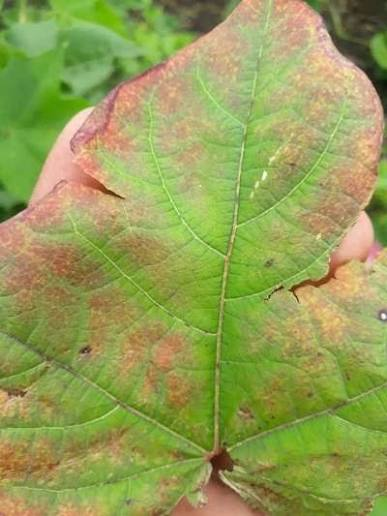


Top prediction: Leaf Redding (100.0%)

Supported-class scores:
  Leaf Redding: 100.0%
  Healthy Leaf: 0.0%
  Leaf Hopper Jassids: 0.0%
  Bacterial Blight: 0.0%
  Curl Virus: 0.0%

Note: OOD rejection has not been trained or calibrated yet.


In [9]:
from google.colab import files
from pathlib import Path
from PIL import Image, ImageOps
import json
import numpy as np
import torch

project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
preprocess = json.loads(
    (project_dir / "preprocessing_config.json").read_text(encoding="utf-8")
)

uploaded = files.upload()
if not uploaded:
    raise RuntimeError("No image was uploaded.")

filename = next(iter(uploaded))
image_path = Path(filename)
if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}:
    raise ValueError(f"Unsupported image type: {image_path.suffix}")

canvas_size = preprocess["canvas_size"]
full_size = preprocess["full_view_size"][0]
tile_size = preprocess["tile_size"][0]
tile_starts = preprocess["tile_starts"]
pad_color = tuple(preprocess["padding_rgb"])

with Image.open(image_path) as im:
    original = ImageOps.exif_transpose(im).convert("RGB")
    display(original.copy())

    im.thumbnail((canvas_size, canvas_size), Image.Resampling.LANCZOS)
    canvas = Image.new("RGB", (canvas_size, canvas_size), pad_color)
    canvas.paste(
        im,
        ((canvas_size - im.width) // 2, (canvas_size - im.height) // 2)
    )

full = canvas.resize((full_size, full_size), Image.Resampling.LANCZOS)
views = [full] + [
    canvas.crop((x, y, x + tile_size, y + tile_size))
    for y in tile_starts
    for x in tile_starts
]

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
tensors = []

for view in views:
    view = view.resize((256, 256), Image.Resampling.LANCZOS)
    arr = np.asarray(view, dtype=np.float32) / 255.0
    tensor = torch.from_numpy(arr).permute(2, 0, 1)
    tensors.append((tensor - mean) / std)

input_tensor = torch.stack(tensors).unsqueeze(0).to(device)

model.eval()
with torch.inference_mode():
    logits = model(input_tensor)
    probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()

ranking = np.argsort(probabilities)[::-1]
print(f"\nTop prediction: {class_names[ranking[0]]} ({probabilities[ranking[0]]:.1%})")
print("\nSupported-class scores:")
for idx in ranking:
    print(f"  {class_names[idx]}: {probabilities[idx]:.1%}")

print("\nNote: OOD rejection has not been trained or calibrated yet.")

In [13]:
from pathlib import Path
from collections import Counter

base = Path("/content/drive/MyDrive/final_year_project/Tea/tea_ood_data")
plantdoc_root = base / "plantdoc_extract"

if not base.exists():
    raise FileNotFoundError(
        f"{base} is not visible in My Drive. In Google Drive, add a shortcut "
        "to the shared tea_ood_data folder under My Drive, then retry."
    )
if not plantdoc_root.exists():
    raise FileNotFoundError(f"Extracted PlantDoc folder not found: {plantdoc_root}")

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
images = [
    p for p in plantdoc_root.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

print(f"PlantDoc folder: {plantdoc_root}")
print(f"Images found: {len(images):,}")
print("\nImage counts by folder:")
counts = Counter(p.parent.relative_to(plantdoc_root).as_posix() for p in images)
for folder, count in sorted(counts.items()):
    print(f"  {folder}: {count:,}")

print("\nTop-level contents:")
for p in sorted(plantdoc_root.iterdir()):
    print(f"  {'[DIR]' if p.is_dir() else '[FILE]'} {p.name}")

PlantDoc folder: /content/drive/MyDrive/final_year_project/Tea/tea_ood_data/plantdoc_extract
Images found: 2,579

Image counts by folder:
  PlantDoc-Dataset-master: 1
  PlantDoc-Dataset-master/test/Apple Scab Leaf: 10
  PlantDoc-Dataset-master/test/Apple leaf: 9
  PlantDoc-Dataset-master/test/Apple rust leaf: 10
  PlantDoc-Dataset-master/test/Bell_pepper leaf: 8
  PlantDoc-Dataset-master/test/Bell_pepper leaf spot: 9
  PlantDoc-Dataset-master/test/Blueberry leaf: 11
  PlantDoc-Dataset-master/test/Cherry leaf: 10
  PlantDoc-Dataset-master/test/Corn Gray leaf spot: 4
  PlantDoc-Dataset-master/test/Corn leaf blight: 12
  PlantDoc-Dataset-master/test/Corn rust leaf: 10
  PlantDoc-Dataset-master/test/Peach leaf: 9
  PlantDoc-Dataset-master/test/Potato leaf early blight: 8
  PlantDoc-Dataset-master/test/Potato leaf late blight: 8
  PlantDoc-Dataset-master/test/Raspberry leaf: 7
  PlantDoc-Dataset-master/test/Soyabean leaf: 8
  PlantDoc-Dataset-master/test/Squash Powdery mildew leaf: 6
  Plan

In [15]:
from pathlib import Path
from collections import Counter
from PIL import Image
from io import BytesIO
import numpy as np
import pandas as pd
import hashlib
import random
import csv
import imagehash

project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
plantdoc_root = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_ood_data/"
    "plantdoc_extract/PlantDoc-Dataset-master"
)
cotton_root = Path(
    "/content/drive/MyDrive/final_year_project/cotton/dataset/"
    "SAR-CLD-2024 A Comprehensive Dataset for Cotton Leaf Disease Detection"
)
cache_root = Path("/content/cotton_cache")
split_manifest_path = project_dir / "split_manifest.csv"
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

for p in [plantdoc_root, cotton_root, cache_root, split_manifest_path]:
    if not p.exists():
        raise FileNotFoundError(p)

def phash_int(image):
    # Convert ImageHash to a compact integer for fast Hamming-distance checks.
    return int(str(imagehash.phash(image)), 16)

# Use up to 20 images per PlantDoc training class, divided between calibration
# and validation. Use the official PlantDoc test folder only as held-out OOD.
train_root = plantdoc_root / "train"
test_root = plantdoc_root / "test"
if not train_root.exists() or not test_root.exists():
    raise FileNotFoundError("Expected PlantDoc train/ and test/ folders.")

ood_records = []
rng = random.Random(20261017)

for class_dir in sorted(p for p in train_root.iterdir() if p.is_dir()):
    candidates = sorted(
        p for p in class_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    )
    rng.shuffle(candidates)
    chosen = candidates[:20]
    midpoint = (len(chosen) + 1) // 2

    for i, path in enumerate(chosen):
        stage = "calibration" if i < midpoint else "validation"
        ood_records.append({
            "stage": stage,
            "category": "other_crop_leaves",
            "plantdoc_class": class_dir.name,
            "source_split": "train",
            "relative_path": str(path.relative_to(plantdoc_root)).replace("\\", "/"),
            "_path": path,
        })

for class_dir in sorted(p for p in test_root.iterdir() if p.is_dir()):
    for path in sorted(
        p for p in class_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    ):
        ood_records.append({
            "stage": "held_out_test",
            "category": "other_crop_leaves",
            "plantdoc_class": class_dir.name,
            "source_split": "test",
            "relative_path": str(path.relative_to(plantdoc_root)).replace("\\", "/"),
            "_path": path,
        })

print(f"Selected PlantDoc images: {len(ood_records):,}")
print("Counts by stage:")
for stage, count in Counter(r["stage"] for r in ood_records).items():
    print(f"  {stage}: {count:,}")

# Build pHashes for the supported cotton cache, which is local to this runtime.
cotton_manifest = pd.read_csv(split_manifest_path)
cotton_hashes = []
for row in cotton_manifest.to_dict("records"):
    cache_name = row["duplicate_group"] + "__" + Path(row["relative_path"]).stem + ".npz"
    cache_file = cache_root / cache_name
    with np.load(cache_file) as data:
        img = Image.fromarray(data["full"])
        cotton_hashes.append((
            row["relative_path"],
            row["label"],
            phash_int(img),
        ))

print(f"\nCotton cached images hashed: {len(cotton_hashes):,}")

# Read each selected PlantDoc file once, validate readability, and hash it.
ood_hashes = []
unreadable = []
for i, row in enumerate(ood_records, 1):
    path = row["_path"]
    try:
        raw = path.read_bytes()
        with Image.open(BytesIO(raw)) as im:
            im.load()
            ph = phash_int(im.convert("RGB"))
        row["sha256"] = hashlib.sha256(raw).hexdigest()
        ood_hashes.append((row, ph, raw))
    except Exception as e:
        unreadable.append((row["relative_path"], repr(e)))

    if i % 100 == 0:
        print(f"Read selected OOD images: {i:,}/{len(ood_records):,}")

# Compare OOD images against cotton pHashes. Matches are candidates for review.
near_cross = []
for row, ood_hash, raw in ood_hashes:
    best_distance = 65
    best_match = None
    for cotton_path, cotton_label, cotton_hash in cotton_hashes:
        distance = (ood_hash ^ cotton_hash).bit_count()
        if distance < best_distance:
            best_distance = distance
            best_match = (cotton_path, cotton_label)

    if best_distance <= 8:
        near_cross.append((best_distance, row, best_match, raw))

# Save selected manifests, excluding the private path/raw-byte fields.
manifest_rows = []
for row, ph, raw in ood_hashes:
    manifest_rows.append({
        "stage": row["stage"],
        "category": row["category"],
        "plantdoc_class": row["plantdoc_class"],
        "source_split": row["source_split"],
        "relative_path": row["relative_path"],
        "sha256": row["sha256"],
    })

manifest_path = project_dir / "plantdoc_ood_manifest.csv"
pd.DataFrame(manifest_rows).to_csv(manifest_path, index=False)

near_path = project_dir / "plantdoc_near_cotton_candidates.csv"
with near_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow([
        "phash_distance", "plantdoc_path", "stage", "plantdoc_class",
        "cotton_path", "cotton_label", "byte_exact_match"
    ])
    for distance, row, match, raw in sorted(near_cross, key=lambda x: x[0]):
        cotton_rel, cotton_label = match
        cotton_file = cotton_root / cotton_rel
        byte_exact = False
        if distance == 0 and cotton_file.exists():
            byte_exact = hashlib.sha256(cotton_file.read_bytes()).digest() == hashlib.sha256(raw).digest()
        writer.writerow([
            distance, row["relative_path"], row["stage"],
            row["plantdoc_class"], cotton_rel, cotton_label, byte_exact
        ])

print(f"\nNear-duplicate candidates vs cotton (pHash distance ≤ 8): {len(near_cross):,}")
print(f"Unreadable selected images: {len(unreadable):,}")
print(f"OOD manifest: {manifest_path}")
print(f"Near-match review list: {near_path}")

if unreadable:
    print("\nUnreadable examples:")
    for path, error in unreadable[:10]:
        print(f"  {path}: {error}")

Selected PlantDoc images: 778
Counts by stage:
  calibration: 271
  validation: 271
  held_out_test: 236

Cotton cached images hashed: 1,648
Read selected OOD images: 100/778
Read selected OOD images: 200/778
Read selected OOD images: 300/778
Read selected OOD images: 400/778
Read selected OOD images: 500/778
Read selected OOD images: 600/778
Read selected OOD images: 700/778

Near-duplicate candidates vs cotton (pHash distance ≤ 8): 0
Unreadable selected images: 0
OOD manifest: /content/drive/MyDrive/final_year_project/cotton/plantdoc_ood_manifest.csv
Near-match review list: /content/drive/MyDrive/final_year_project/cotton/plantdoc_near_cotton_candidates.csv


In [16]:
from pathlib import Path
from PIL import Image, ImageOps
import numpy as np
import pandas as pd
import json
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
plantdoc_root = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_ood_data/"
    "plantdoc_extract/PlantDoc-Dataset-master"
)
dataset_root = Path(
    "/content/drive/MyDrive/final_year_project/cotton/dataset/"
    "SAR-CLD-2024 A Comprehensive Dataset for Cotton Leaf Disease Detection"
)
cache_root = Path("/content/cotton_cache")

# Ensure the selected best checkpoint is active.
checkpoint_path = project_dir / "checkpoints" / "best_model.pt"
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.eval()

manifest = pd.read_csv(project_dir / "split_manifest.csv")
train_df = manifest[manifest["split"] == "train"].reset_index(drop=True)
val_df = manifest[manifest["split"] == "validation"].reset_index(drop=True)
test_df = manifest[manifest["split"] == "internal_test"].reset_index(drop=True)

ood_manifest = pd.read_csv(project_dir / "plantdoc_ood_manifest.csv")
prep = json.loads((project_dir / "preprocessing_config.json").read_text())
canvas_size = prep["canvas_size"]
full_size = prep["full_view_size"][0]
tile_size = prep["tile_size"][0]
tile_starts = prep["tile_starts"]
pad_color = tuple(prep["padding_rgb"])
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def image_to_views(path):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
    im.thumbnail((canvas_size, canvas_size), Image.Resampling.LANCZOS)
    canvas = Image.new("RGB", (canvas_size, canvas_size), pad_color)
    canvas.paste(im, ((canvas_size - im.width) // 2, (canvas_size - im.height) // 2))
    views = [canvas.resize((full_size, full_size), Image.Resampling.LANCZOS)]
    views += [
        canvas.crop((x, y, x + tile_size, y + tile_size))
        for y in tile_starts for x in tile_starts
    ]
    result = []
    for view in views:
        view = view.resize((256, 256), Image.Resampling.LANCZOS)
        arr = np.asarray(view, dtype=np.float32) / 255.0
        tensor = torch.from_numpy(arr).permute(2, 0, 1)
        result.append((tensor - mean) / std)
    return torch.stack(result)

class PlantDocOODDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        path = plantdoc_root / row["relative_path"]
        return image_to_views(path), row["stage"], row["relative_path"], row["plantdoc_class"]

def extract_cotton(dataframe, split_name):
    loader = DataLoader(
        CottonValDataset(dataframe),
        batch_size=2, shuffle=False, num_workers=2,
        pin_memory=(device.type == "cuda")
    )
    embeddings, confidences, labels, paths = [], [], [], []
    with torch.inference_mode():
        for views, y, batch_paths in loader:
            views = views.to(device)
            features = model.encode_views(views)
            logits = model.classifier(model.dropout(features))
            probs = torch.softmax(logits, dim=1)
            embeddings.append(F.normalize(features, dim=1).cpu().numpy())
            confidences.extend(probs.max(dim=1).values.cpu().numpy().tolist())
            labels.extend(y.numpy().tolist())
            paths.extend(batch_paths)
    return {
        "embeddings": np.concatenate(embeddings),
        "confidence": np.asarray(confidences, dtype=np.float32),
        "labels": np.asarray(labels, dtype=np.int64),
        "paths": paths,
        "split": split_name,
    }

def extract_ood(dataframe):
    loader = DataLoader(
        PlantDocOODDataset(dataframe),
        batch_size=2, shuffle=False, num_workers=2,
        pin_memory=(device.type == "cuda")
    )
    by_stage = {}
    with torch.inference_mode():
        for views, stages, batch_paths, source_classes in loader:
            views = views.to(device)
            features = model.encode_views(views)
            logits = model.classifier(model.dropout(features))
            probs = torch.softmax(logits, dim=1)
            emb = F.normalize(features, dim=1).cpu().numpy()
            conf = probs.max(dim=1).values.cpu().numpy()
            for i, stage in enumerate(stages):
                by_stage.setdefault(stage, {"embeddings": [], "confidence": [], "paths": [], "source_classes": []})
                by_stage[stage]["embeddings"].append(emb[i])
                by_stage[stage]["confidence"].append(float(conf[i]))
                by_stage[stage]["paths"].append(batch_paths[i])
                by_stage[stage]["source_classes"].append(source_classes[i])

    for stage, data in by_stage.items():
        data["embeddings"] = np.stack(data["embeddings"])
        data["confidence"] = np.asarray(data["confidence"], dtype=np.float32)
    return by_stage

print("Extracting cotton training reference embeddings...")
train_scores = extract_cotton(train_df, "train_reference")
print("Extracting cotton validation scores...")
val_scores = extract_cotton(val_df, "supported_validation")
print("Extracting PlantDoc OOD scores...")
ood_scores = extract_ood(ood_manifest)

# kNN similarity is the mean cosine similarity of the five nearest cotton-training embeddings.
reference = train_scores["embeddings"]
def add_knn_scores(score_data):
    sims = score_data["embeddings"] @ reference.T
    topk = min(5, sims.shape[1])
    score_data["knn_similarity"] = np.partition(sims, -topk, axis=1)[:, -topk:].mean(axis=1)

add_knn_scores(val_scores)
for stage_data in ood_scores.values():
    add_knn_scores(stage_data)

# Save arrays and a separate JSON index for reproducibility.
arrays = {
    "cotton_reference_embeddings": reference.astype(np.float32),
    "supported_validation_embeddings": val_scores["embeddings"].astype(np.float32),
    "supported_validation_confidence": val_scores["confidence"],
    "supported_validation_knn": val_scores["knn_similarity"].astype(np.float32),
    "supported_validation_labels": val_scores["labels"],
}
index = {
    "checkpoint": str(checkpoint_path),
    "checkpoint_epoch": int(checkpoint["best_epoch"]),
    "class_names": checkpoint["class_names"],
    "supported_validation_paths": val_scores["paths"],
    "ood": {},
}
for stage, data in ood_scores.items():
    key = f"ood_{stage}"
    arrays[f"{key}_embeddings"] = data["embeddings"].astype(np.float32)
    arrays[f"{key}_confidence"] = data["confidence"]
    arrays[f"{key}_knn"] = data["knn_similarity"].astype(np.float32)
    index["ood"][stage] = {
        "paths": data["paths"],
        "source_classes": data["source_classes"],
        "count": len(data["paths"]),
    }

np.savez_compressed(project_dir / "ood_scores_and_embeddings.npz", **arrays)
(project_dir / "ood_scores_index.json").write_text(json.dumps(index, indent=2), encoding="utf-8")

print("\nScores saved.")
print(f"Cotton reference embeddings: {len(reference):,}")
print(f"Supported validation: {len(val_scores['paths']):,}")
for stage, data in ood_scores.items():
    print(f"PlantDoc {stage}: {len(data['paths']):,}")
print(f"Artifacts: {project_dir / 'ood_scores_and_embeddings.npz'}")

Extracting cotton training reference embeddings...


AttributeError: 'CottonResNet50Fusion' object has no attribute 'encode_views'

In [17]:
from types import MethodType
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

def encode_views(self, x):
    batch, views, channels, height, width = x.shape
    x = x.reshape(batch * views, channels, height, width)

    x = self.stem(x)
    x = self.layer1(x)
    f2 = self.layer2(x)
    f3 = self.layer3(f2)
    f4 = self.layer4(f3)

    target_size = f4.shape[-2:]
    p2 = F.adaptive_avg_pool2d(self.proj2(f2), target_size)
    p3 = F.adaptive_avg_pool2d(self.proj3(f3), target_size)
    p4 = self.proj4(f4)
    fused = self.fuse(torch.cat([p2, p3, p4], dim=1))
    fused = self.attention(fused)
    features = self.pool(fused).flatten(1)
    return features.view(batch, views, -1).mean(dim=1)

model.encode_views = MethodType(encode_views, model)
model.eval()

def extract_cotton_scores(dataframe):
    loader = DataLoader(
        CottonValDataset(dataframe),
        batch_size=2,
        shuffle=False,
        num_workers=2,
        pin_memory=(device.type == "cuda"),
    )
    embeddings, confidences, labels, paths = [], [], [], []
    with torch.inference_mode():
        for views, y, batch_paths in loader:
            features = model.encode_views(views.to(device))
            logits = model.classifier(model.dropout(features))
            probs = torch.softmax(logits, dim=1)
            embeddings.append(F.normalize(features, dim=1).cpu().numpy())
            confidences.extend(probs.max(dim=1).values.cpu().numpy().tolist())
            labels.extend(y.numpy().tolist())
            paths.extend(batch_paths)
    return {
        "embeddings": np.concatenate(embeddings),
        "confidence": np.asarray(confidences, dtype=np.float32),
        "labels": np.asarray(labels, dtype=np.int64),
        "paths": paths,
    }

def extract_ood_scores(dataframe):
    loader = DataLoader(
        PlantDocOODDataset(dataframe),
        batch_size=2,
        shuffle=False,
        num_workers=2,
        pin_memory=(device.type == "cuda"),
    )
    result = {}
    with torch.inference_mode():
        for views, stages, batch_paths, source_classes in loader:
            features = model.encode_views(views.to(device))
            logits = model.classifier(model.dropout(features))
            probs = torch.softmax(logits, dim=1)
            embeddings = F.normalize(features, dim=1).cpu().numpy()
            confidences = probs.max(dim=1).values.cpu().numpy()

            for i, stage in enumerate(stages):
                item = result.setdefault(stage, {
                    "embeddings": [], "confidence": [],
                    "paths": [], "source_classes": []
                })
                item["embeddings"].append(embeddings[i])
                item["confidence"].append(float(confidences[i]))
                item["paths"].append(batch_paths[i])
                item["source_classes"].append(source_classes[i])

    for item in result.values():
        item["embeddings"] = np.stack(item["embeddings"])
        item["confidence"] = np.asarray(item["confidence"], dtype=np.float32)
    return result

print("Extracting cotton training reference embeddings...")
train_scores = extract_cotton_scores(train_df)
reference = train_scores["embeddings"]

print("Extracting cotton validation scores...")
val_scores = extract_cotton_scores(val_df)

print("Extracting PlantDoc OOD scores...")
ood_scores = extract_ood_scores(ood_manifest)

def add_knn_score(data):
    similarities = data["embeddings"] @ reference.T
    k = min(5, similarities.shape[1])
    data["knn_similarity"] = np.partition(
        similarities, -k, axis=1
    )[:, -k:].mean(axis=1)

add_knn_score(val_scores)
for data in ood_scores.values():
    add_knn_score(data)

arrays = {
    "cotton_reference_embeddings": reference.astype(np.float32),
    "supported_validation_embeddings": val_scores["embeddings"].astype(np.float32),
    "supported_validation_confidence": val_scores["confidence"],
    "supported_validation_knn": val_scores["knn_similarity"].astype(np.float32),
    "supported_validation_labels": val_scores["labels"],
}
index = {
    "checkpoint_epoch": int(checkpoint["best_epoch"]),
    "class_names": checkpoint["class_names"],
    "supported_validation_paths": val_scores["paths"],
    "ood": {},
}

for stage, data in ood_scores.items():
    prefix = f"ood_{stage}"
    arrays[f"{prefix}_embeddings"] = data["embeddings"].astype(np.float32)
    arrays[f"{prefix}_confidence"] = data["confidence"]
    arrays[f"{prefix}_knn"] = data["knn_similarity"].astype(np.float32)
    index["ood"][stage] = {
        "paths": data["paths"],
        "source_classes": data["source_classes"],
        "count": len(data["paths"]),
    }

project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
np.savez_compressed(project_dir / "ood_scores_and_embeddings.npz", **arrays)
(project_dir / "ood_scores_index.json").write_text(
    __import__("json").dumps(index, indent=2), encoding="utf-8"
)

print("\nOOD score and embedding extraction complete.")
print(f"Training reference images: {len(reference):,}")
print(f"Supported validation images: {len(val_scores['paths']):,}")
for stage, data in ood_scores.items():
    print(f"PlantDoc {stage}: {len(data['paths']):,}")
print(f"Saved to: {project_dir / 'ood_scores_and_embeddings.npz'}")

Extracting cotton training reference embeddings...
Extracting cotton validation scores...
Extracting PlantDoc OOD scores...

OOD score and embedding extraction complete.
Training reference images: 1,149
Supported validation images: 249
PlantDoc calibration: 271
PlantDoc validation: 271
PlantDoc held_out_test: 236
Saved to: /content/drive/MyDrive/final_year_project/cotton/ood_scores_and_embeddings.npz


In [18]:
from pathlib import Path
import json
import numpy as np

project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
scores_path = project_dir / "ood_scores_and_embeddings.npz"
if not scores_path.exists():
    raise FileNotFoundError(scores_path)

scores = np.load(scores_path)
support_conf = scores["supported_validation_confidence"]
support_knn = scores["supported_validation_knn"]
cal_conf = scores["ood_calibration_confidence"]
cal_knn = scores["ood_calibration_knn"]
ood_val_conf = scores["ood_validation_confidence"]
ood_val_knn = scores["ood_validation_knn"]

target_support_acceptance = 0.99

# Search thresholds that maximize calibration-OOD rejection while retaining
# at least 99% of the supported validation images.
conf_candidates = np.unique(support_conf)
knn_candidates = np.unique(support_knn)

best = None
for conf_threshold in conf_candidates:
    support_conf_ok = support_conf >= conf_threshold
    cal_conf_ok = cal_conf >= conf_threshold

    for knn_threshold in knn_candidates:
        support_accepted = support_conf_ok & (support_knn >= knn_threshold)
        support_rate = float(support_accepted.mean())
        if support_rate + 1e-12 < target_support_acceptance:
            continue

        cal_accepted = cal_conf_ok & (cal_knn >= knn_threshold)
        cal_rejection = float((~cal_accepted).mean())

        candidate = (cal_rejection, support_rate, conf_threshold, knn_threshold)
        if best is None or candidate[:2] > best[:2]:
            best = candidate

if best is None:
    raise RuntimeError("No threshold pair met the requested supported acceptance target.")

cal_rejection, support_rate, conf_threshold, knn_threshold = best

def policy_stats(confidence, similarity):
    accepted = (confidence >= conf_threshold) & (similarity >= knn_threshold)
    return {
        "count": int(len(accepted)),
        "accepted": int(accepted.sum()),
        "rejected": int((~accepted).sum()),
        "acceptance_rate": float(accepted.mean()),
        "rejection_rate": float((~accepted).mean()),
    }

cal_stats = policy_stats(cal_conf, cal_knn)
ood_val_stats = policy_stats(ood_val_conf, ood_val_knn)
support_stats = policy_stats(support_conf, support_knn)

config = {
    "policy": "reject if max_softmax_confidence < threshold OR mean_top5_cosine_similarity < threshold",
    "confidence_threshold": float(conf_threshold),
    "knn_similarity_threshold": float(knn_threshold),
    "knn": {"reference": "cotton training embeddings", "k": 5, "aggregation": "mean cosine similarity"},
    "target_supported_validation_acceptance": target_support_acceptance,
    "checkpoint_epoch": int(checkpoint["best_epoch"]),
    "selection_data": {
        "supported": "cotton validation split",
        "ood": "PlantDoc calibration split",
    },
    "calibration_results": {
        "supported_validation": support_stats,
        "plantdoc_calibration": cal_stats,
    },
    "frozen_ood_validation_results": {
        "plantdoc_validation": ood_val_stats,
    },
    "held_out_test_used_for_threshold_selection": False,
}
config_path = project_dir / "ood_reliability_config.json"
config_path.write_text(json.dumps(config, indent=2), encoding="utf-8")

print(f"Confidence threshold: {conf_threshold:.6f}")
print(f"kNN similarity threshold: {knn_threshold:.6f}")
print(f"\nSupported cotton validation: {support_stats}")
print(f"PlantDoc calibration: {cal_stats}")
print(f"PlantDoc validation (frozen policy): {ood_val_stats}")
print(f"\nFrozen policy saved: {config_path}")

Confidence threshold: 0.413562
kNN similarity threshold: 0.868609

Supported cotton validation: {'count': 249, 'accepted': 247, 'rejected': 2, 'acceptance_rate': 0.9919678714859438, 'rejection_rate': 0.008032128514056224}
PlantDoc calibration: {'count': 271, 'accepted': 187, 'rejected': 84, 'acceptance_rate': 0.6900369003690037, 'rejection_rate': 0.30996309963099633}
PlantDoc validation (frozen policy): {'count': 271, 'accepted': 180, 'rejected': 91, 'acceptance_rate': 0.6642066420664207, 'rejection_rate': 0.33579335793357934}

Frozen policy saved: /content/drive/MyDrive/final_year_project/cotton/ood_reliability_config.json


In [19]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
policy = json.loads((project_dir / "ood_reliability_config.json").read_text())
score_archive = np.load(project_dir / "ood_scores_and_embeddings.npz")
score_index = json.loads((project_dir / "ood_scores_index.json").read_text())

conf_threshold = policy["confidence_threshold"]
knn_threshold = policy["knn_similarity_threshold"]
reference = score_archive["cotton_reference_embeddings"]

# Score the held-out supported cotton test once under the frozen policy.
manifest = pd.read_csv(project_dir / "split_manifest.csv")
test_df = manifest[manifest["split"] == "internal_test"].reset_index(drop=True)
test_loader = DataLoader(
    CottonValDataset(test_df),
    batch_size=2,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
)

test_labels, test_preds, test_conf, test_knn, test_paths = [], [], [], [], []
with torch.inference_mode():
    for views, labels, paths in test_loader:
        features = model.encode_views(views.to(device))
        logits = model.classifier(model.dropout(features))
        probs = torch.softmax(logits, dim=1)
        embeddings = F.normalize(features, dim=1).cpu().numpy()
        similarities = embeddings @ reference.T
        k = min(5, similarities.shape[1])
        knn = np.partition(similarities, -k, axis=1)[:, -k:].mean(axis=1)

        test_labels.extend(labels.numpy().tolist())
        test_preds.extend(logits.argmax(dim=1).cpu().tolist())
        test_conf.extend(probs.max(dim=1).values.cpu().numpy().tolist())
        test_knn.extend(knn.tolist())
        test_paths.extend(paths)

test_labels = np.asarray(test_labels)
test_preds = np.asarray(test_preds)
test_conf = np.asarray(test_conf)
test_knn = np.asarray(test_knn)
test_accept = (test_conf >= conf_threshold) & (test_knn >= knn_threshold)

supported_results = {
    "count": int(len(test_labels)),
    "accepted": int(test_accept.sum()),
    "rejected": int((~test_accept).sum()),
    "acceptance_rate": float(test_accept.mean()),
    "rejection_rate": float((~test_accept).mean()),
    "classifier_accuracy_before_rejection": float(accuracy_score(test_labels, test_preds)),
    "balanced_accuracy_before_rejection": float(balanced_accuracy_score(test_labels, test_preds)),
    "macro_f1_before_rejection": float(f1_score(test_labels, test_preds, average="macro", zero_division=0)),
    "accuracy_on_accepted_images": (
        float(accuracy_score(test_labels[test_accept], test_preds[test_accept]))
        if test_accept.any() else None
    ),
    "correct_and_accepted_fraction_of_all_test_images": float(
        np.mean((test_labels == test_preds) & test_accept)
    ),
}

class_names = checkpoint["class_names"]
supported_predictions = []
for i, path in enumerate(test_paths):
    supported_predictions.append({
        "relative_path": path,
        "true_label": class_names[int(test_labels[i])],
        "predicted_label": class_names[int(test_preds[i])],
        "confidence": float(test_conf[i]),
        "knn_similarity": float(test_knn[i]),
        "policy_result": "accept" if test_accept[i] else "reject",
    })

# Apply the same frozen policy to the untouched PlantDoc test set.
ood_conf = score_archive["ood_held_out_test_confidence"]
ood_knn = score_archive["ood_held_out_test_knn"]
ood_accept = (ood_conf >= conf_threshold) & (ood_knn >= knn_threshold)
heldout_info = score_index["ood"]["held_out_test"]

ood_by_class = {}
for source_class in sorted(set(heldout_info["source_classes"])):
    idxs = [i for i, name in enumerate(heldout_info["source_classes"]) if name == source_class]
    count = len(idxs)
    accepted = int(ood_accept[idxs].sum())
    ood_by_class[source_class] = {
        "count": count,
        "accepted_as_supported": accepted,
        "rejected_as_ood": count - accepted,
        "ood_rejection_rate": float((count - accepted) / count),
    }

ood_results = {
    "count": int(len(ood_accept)),
    "accepted_as_supported": int(ood_accept.sum()),
    "rejected_as_ood": int((~ood_accept).sum()),
    "acceptance_rate": float(ood_accept.mean()),
    "rejection_rate": float((~ood_accept).mean()),
    "by_plantdoc_class": ood_by_class,
}

report = {
    "policy": {
        "confidence_threshold": conf_threshold,
        "knn_similarity_threshold": knn_threshold,
        "thresholds_changed": False,
    },
    "held_out_supported_internal_test": supported_results,
    "held_out_ood_plantdoc_test": ood_results,
    "ood_categories_tested": ["other-crop leaves from PlantDoc"],
    "ood_categories_not_tested": ["non-plant images", "unsupported cotton conditions"],
}

(project_dir / "ood_frozen_policy_test_report.json").write_text(
    json.dumps(report, indent=2), encoding="utf-8"
)
pd.DataFrame(supported_predictions).to_csv(
    project_dir / "ood_internal_test_predictions.csv", index=False
)

ood_predictions = pd.DataFrame({
    "relative_path": heldout_info["paths"],
    "plantdoc_class": heldout_info["source_classes"],
    "confidence": ood_conf,
    "knn_similarity": ood_knn,
    "policy_result": np.where(ood_accept, "accepted_as_supported", "rejected_as_ood"),
})
ood_predictions.to_csv(project_dir / "plantdoc_held_out_policy_predictions.csv", index=False)

print("Frozen policy results (thresholds unchanged)")
print(f"\nCotton internal test: {supported_results}")
print(f"\nPlantDoc held-out OOD test: {ood_results}")
print(f"\nFull report: {project_dir / 'ood_frozen_policy_test_report.json'}")
print(f"Cotton predictions: {project_dir / 'ood_internal_test_predictions.csv'}")
print(f"OOD predictions: {project_dir / 'plantdoc_held_out_policy_predictions.csv'}")

Frozen policy results (thresholds unchanged)

Cotton internal test: {'count': 250, 'accepted': 246, 'rejected': 4, 'acceptance_rate': 0.984, 'rejection_rate': 0.016, 'classifier_accuracy_before_rejection': 0.928, 'balanced_accuracy_before_rejection': 0.9434776987718164, 'macro_f1_before_rejection': 0.930636687643057, 'accuracy_on_accepted_images': 0.9308943089430894, 'correct_and_accepted_fraction_of_all_test_images': 0.916}

PlantDoc held-out OOD test: {'count': 236, 'accepted_as_supported': 158, 'rejected_as_ood': 78, 'acceptance_rate': 0.6694915254237288, 'rejection_rate': 0.3305084745762712, 'by_plantdoc_class': {'Apple Scab Leaf': {'count': 10, 'accepted_as_supported': 4, 'rejected_as_ood': 6, 'ood_rejection_rate': 0.6}, 'Apple leaf': {'count': 9, 'accepted_as_supported': 7, 'rejected_as_ood': 2, 'ood_rejection_rate': 0.2222222222222222}, 'Apple rust leaf': {'count': 10, 'accepted_as_supported': 8, 'rejected_as_ood': 2, 'ood_rejection_rate': 0.2}, 'Bell_pepper leaf': {'count': 8, 

In [20]:
from pathlib import Path
import numpy as np
import pandas as pd

project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
scores = np.load(project_dir / "ood_scores_and_embeddings.npz")

support_conf = scores["supported_validation_confidence"]
support_knn = scores["supported_validation_knn"]
cal_conf = scores["ood_calibration_confidence"]
cal_knn = scores["ood_calibration_knn"]

conf_candidates = np.unique(support_conf)
knn_candidates = np.unique(support_knn)

rows = []
for target_acceptance in [0.99, 0.97, 0.95, 0.90, 0.85]:
    best = None

    for conf_threshold in conf_candidates:
        support_conf_ok = support_conf >= conf_threshold
        cal_conf_ok = cal_conf >= conf_threshold

        for knn_threshold in knn_candidates:
            support_accept = support_conf_ok & (support_knn >= knn_threshold)
            support_rate = float(support_accept.mean())
            if support_rate + 1e-12 < target_acceptance:
                continue

            cal_accept = cal_conf_ok & (cal_knn >= knn_threshold)
            cal_reject_rate = float((~cal_accept).mean())
            candidate = (cal_reject_rate, support_rate, conf_threshold, knn_threshold)
            if best is None or candidate[:2] > best[:2]:
                best = candidate

    rows.append({
        "minimum_supported_validation_acceptance": target_acceptance,
        "actual_supported_validation_acceptance": best[1],
        "plantdoc_calibration_rejection": best[0],
        "confidence_threshold": best[2],
        "knn_similarity_threshold": best[3],
    })

tradeoff = pd.DataFrame(rows)
out_path = project_dir / "ood_threshold_tradeoff_calibration_only.csv"
tradeoff.to_csv(out_path, index=False)

print(tradeoff.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\nSaved calibration-only tradeoff table: {out_path}")

 minimum_supported_validation_acceptance  actual_supported_validation_acceptance  plantdoc_calibration_rejection  confidence_threshold  knn_similarity_threshold
                                  0.9900                                  0.9920                          0.3100                0.4136                    0.8686
                                  0.9700                                  0.9719                          0.4760                0.4136                    0.9056
                                  0.9500                                  0.9518                          0.7159                0.4136                    0.9417
                                  0.9000                                  0.9036                          0.8044                0.4136                    0.9601
                                  0.8500                                  0.8514                          0.9114                0.4136                    0.9754

Saved calibration-only tradeoff t

In [21]:
from pathlib import Path
import pandas as pd
import random

project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
plantdoc_root = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_ood_data/"
    "plantdoc_extract/PlantDoc-Dataset-master"
)
existing_manifest_path = project_dir / "plantdoc_ood_manifest.csv"

if not existing_manifest_path.exists():
    raise FileNotFoundError(existing_manifest_path)

existing = pd.read_csv(existing_manifest_path)
used_paths = set(existing["relative_path"].astype(str))
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
rng = random.Random(20261018)

records = []
excluded_classes = []

train_root = plantdoc_root / "train"
for class_dir in sorted(p for p in train_root.iterdir() if p.is_dir()):
    if "cotton" in class_dir.name.casefold():
        excluded_classes.append(class_dir.name)
        continue

    candidates = sorted(
        p for p in class_dir.rglob("*")
        if p.is_file()
        and p.suffix.lower() in extensions
        and str(p.relative_to(plantdoc_root)).replace("\\", "/") not in used_paths
    )
    rng.shuffle(candidates)

    if len(candidates) >= 2:
        holdout_count = min(10, max(1, len(candidates) // 5))
    else:
        holdout_count = 0

    heldout = candidates[:holdout_count]
    exposure = candidates[holdout_count:]

    for path in exposure:
        records.append({
            "stage": "outlier_exposure",
            "category": "other_crop_leaves",
            "plantdoc_class": class_dir.name,
            "relative_path": str(path.relative_to(plantdoc_root)).replace("\\", "/"),
        })
    for path in heldout:
        records.append({
            "stage": "fresh_held_out_test",
            "category": "other_crop_leaves",
            "plantdoc_class": class_dir.name,
            "relative_path": str(path.relative_to(plantdoc_root)).replace("\\", "/"),
        })

manifest = pd.DataFrame(records)
if manifest.empty:
    raise RuntimeError("No unused PlantDoc training images were available.")
if manifest["relative_path"].duplicated().any():
    raise RuntimeError("A PlantDoc image was assigned more than once.")
if set(manifest["relative_path"]) & used_paths:
    raise RuntimeError("An image already used in a prior OOD split was reassigned.")

out_path = project_dir / "plantdoc_finetune_manifest.csv"
manifest.to_csv(out_path, index=False)

print(f"Unused PlantDoc images assigned: {len(manifest):,}")
print("\nCounts by stage:")
print(manifest["stage"].value_counts().to_string())
print("\nCounts by stage and PlantDoc class:")
print(pd.crosstab(manifest["plantdoc_class"], manifest["stage"]).to_string())
print(f"\nManifest saved: {out_path}")
if excluded_classes:
    print(f"Classes excluded because their name contains cotton: {excluded_classes}")

Unused PlantDoc images assigned: 1,800

Counts by stage:
stage
outlier_exposure       1561
fresh_held_out_test     239

Counts by stage and PlantDoc class:
stage                       fresh_held_out_test  outlier_exposure
plantdoc_class                                                   
Apple Scab Leaf                              10                53
Apple leaf                                   10                52
Apple rust leaf                              10                49
Bell_pepper leaf                              6                27
Bell_pepper leaf spot                         8                34
Blueberry leaf                               10                76
Cherry leaf                                   5                22
Corn Gray leaf spot                           8                36
Corn leaf blight                             10               150
Corn rust leaf                               10                76
Peach leaf                                   10     

In [22]:
from pathlib import Path
import json
import shutil
import numpy as np
import torch

project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
package_dir = project_dir / "cotton_model_package_v1"
package_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = project_dir / "checkpoints" / "best_model.pt"
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
class_names = checkpoint["class_names"]

# Freeze the already evaluated conservative thresholds.
reliability = json.loads(
    (project_dir / "ood_reliability_config.json").read_text(encoding="utf-8")
)
reliability["confidence_threshold"] = 0.413562
reliability["knn_similarity_threshold"] = 0.868609
reliability["fine_tuned_on_ood"] = False
reliability["final_policy_frozen"] = True
(package_dir / "ood_reliability_config.json").write_text(
    json.dumps(reliability, indent=2), encoding="utf-8"
)

# Save selected weights without training/resume metadata.
torch.save(checkpoint["model_state_dict"], package_dir / "model_weights.pt")

# Save the cotton training reference embeddings used by the kNN score.
scores = np.load(project_dir / "ood_scores_and_embeddings.npz")
np.savez_compressed(
    package_dir / "reference_embeddings.npz",
    embeddings=scores["cotton_reference_embeddings"].astype(np.float32),
)

# Preserve the exact preprocessing configuration used in training and scoring.
shutil.copy2(
    project_dir / "preprocessing_config.json",
    package_dir / "preprocessing_config.json",
)

model_config = {
    "crop": "cotton",
    "architecture": "CottonResNet50Fusion",
    "checkpoint_epoch": int(checkpoint["best_epoch"]),
    "class_names": class_names,
    "class_to_idx": {name: i for i, name in enumerate(class_names)},
    "input_views": ["full_leaf", "tile_top_left", "tile_top_right",
                    "tile_bottom_left", "tile_bottom_right"],
    "input_tensor_size": [5, 3, 256, 256],
    "weights_file": "model_weights.pt",
    "reference_embeddings_file": "reference_embeddings.npz",
    "preprocessing_file": "preprocessing_config.json",
    "reliability_file": "ood_reliability_config.json",
}
(package_dir / "model_config.json").write_text(
    json.dumps(model_config, indent=2), encoding="utf-8"
)

model_py = r'''
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet50

class SpatialSelfAttention(nn.Module):
    def __init__(self, channels):
        super().__init__()
        inner = max(channels // 8, 32)
        self.query = nn.Conv2d(channels, inner, 1)
        self.key = nn.Conv2d(channels, inner, 1)
        self.value = nn.Conv2d(channels, channels, 1)
        self.gamma = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        batch, channels, height, width = x.shape
        q = self.query(x).flatten(2).transpose(1, 2)
        k = self.key(x).flatten(2)
        attention = torch.softmax(
            torch.bmm(q, k) / (q.shape[-1] ** 0.5), dim=-1
        )
        v = self.value(x).flatten(2)
        attended = torch.bmm(v, attention.transpose(1, 2)).view(
            batch, channels, height, width
        )
        return x + self.gamma * attended

class CottonResNet50Fusion(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        backbone = resnet50(weights=None)
        self.stem = nn.Sequential(
            backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool
        )
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        self.proj2 = nn.Conv2d(512, 256, 1)
        self.proj3 = nn.Conv2d(1024, 256, 1)
        self.proj4 = nn.Conv2d(2048, 256, 1)
        self.fuse = nn.Sequential(
            nn.Conv2d(768, 512, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
        )
        self.attention = SpatialSelfAttention(512)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(0.35)
        self.classifier = nn.Linear(512, num_classes)

    def encode_views(self, x):
        batch, views, channels, height, width = x.shape
        x = x.reshape(batch * views, channels, height, width)
        x = self.stem(x)
        x = self.layer1(x)
        f2 = self.layer2(x)
        f3 = self.layer3(f2)
        f4 = self.layer4(f3)

        target_size = f4.shape[-2:]
        p2 = F.adaptive_avg_pool2d(self.proj2(f2), target_size)
        p3 = F.adaptive_avg_pool2d(self.proj3(f3), target_size)
        p4 = self.proj4(f4)
        fused = self.fuse(torch.cat([p2, p3, p4], dim=1))
        fused = self.attention(fused)
        features = self.pool(fused).flatten(1)
        return features.view(batch, views, -1).mean(dim=1)

    def forward(self, x):
        features = self.encode_views(x)
        return self.classifier(self.dropout(features))
'''
(package_dir / "model.py").write_text(model_py.strip() + "\n", encoding="utf-8")

inference_py = r'''
import json
from pathlib import Path

import numpy as np
from PIL import Image, ImageOps
import torch
import torch.nn.functional as F

try:
    from .model import CottonResNet50Fusion
except ImportError:
    from model import CottonResNet50Fusion

def load_package(package_dir, device=None):
    package_dir = Path(package_dir)
    device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))

    config = json.loads((package_dir / "model_config.json").read_text())
    prep = json.loads((package_dir / config["preprocessing_file"]).read_text())
    policy = json.loads((package_dir / config["reliability_file"]).read_text())

    model = CottonResNet50Fusion(len(config["class_names"]))
    try:
        weights = torch.load(
            package_dir / config["weights_file"],
            map_location=device,
            weights_only=True,
        )
    except TypeError:
        weights = torch.load(package_dir / config["weights_file"], map_location=device)

    model.load_state_dict(weights, strict=True)
    model.to(device).eval()

    reference = np.load(package_dir / config["reference_embeddings_file"])["embeddings"]
    reference = torch.as_tensor(reference, dtype=torch.float32, device=device)
    reference = F.normalize(reference, dim=1)

    return model, config, prep, policy, reference, device

def prepare_views(image, prep):
    canvas_size = prep["canvas_size"]
    pad_color = tuple(prep["padding_rgb"])

    image = ImageOps.exif_transpose(image).convert("RGB")
    image.thumbnail((canvas_size, canvas_size), Image.Resampling.LANCZOS)
    canvas = Image.new("RGB", (canvas_size, canvas_size), pad_color)
    canvas.paste(
        image,
        ((canvas_size - image.width) // 2, (canvas_size - image.height) // 2),
    )

    full_size = prep["full_view_size"][0]
    tile_size = prep["tile_size"][0]
    starts = prep["tile_starts"]
    views = [canvas.resize((full_size, full_size), Image.Resampling.LANCZOS)]
    views += [
        canvas.crop((x, y, x + tile_size, y + tile_size))
        for y in starts for x in starts
    ]

    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    tensors = []
    for view in views:
        view = view.resize((256, 256), Image.Resampling.LANCZOS)
        arr = np.asarray(view, dtype=np.float32) / 255.0
        tensor = torch.from_numpy(arr).permute(2, 0, 1)
        tensors.append((tensor - mean) / std)
    return torch.stack(tensors).unsqueeze(0)

@torch.inference_mode()
def predict(image_path, package_dir, device=None):
    model, config, prep, policy, reference, device = load_package(package_dir, device)
    with Image.open(image_path) as image:
        x = prepare_views(image, prep).to(device)

    features = model.encode_views(x)
    logits = model.classifier(model.dropout(features))
    probabilities = torch.softmax(logits, dim=1)[0]
    confidence, class_idx = probabilities.max(dim=0)

    embedding = F.normalize(features, dim=1)
    similarities = embedding @ reference.T
    k = min(5, similarities.shape[1])
    knn_similarity = similarities.topk(k, dim=1).values.mean().item()

    accepted = (
        confidence.item() >= policy["confidence_threshold"]
        and knn_similarity >= policy["knn_similarity_threshold"]
    )
    return {
        "decision": "accept" if accepted else "REJECT_OOD",
        "predicted_class": config["class_names"][class_idx.item()] if accepted else None,
        "top_supported_class": config["class_names"][class_idx.item()],
        "confidence": confidence.item(),
        "knn_similarity": knn_similarity,
        "class_probabilities": {
            name: float(probabilities[i])
            for i, name in enumerate(config["class_names"])
        },
    }
'''
(package_dir / "inference.py").write_text(inference_py.strip() + "\n", encoding="utf-8")

# Include evaluation evidence and concise scope notes.
for filename in [
    "internal_test_report.json",
    "ood_frozen_policy_test_report.json",
]:
    source = project_dir / filename
    if source.exists():
        shutil.copy2(source, package_dir / filename)

readme = """# Cotton model package v1

This package predicts one of five supported cotton leaf classes and applies a frozen
confidence plus kNN similarity rejection policy.

The OOD policy was tested on PlantDoc other-crop leaves, including grape leaves.
Non-plant images and unsupported cotton conditions were not tested. OOD rejection
is not guaranteed for every unfamiliar input.

The conservative frozen thresholds prioritize cotton-image acceptance. See
`ood_frozen_policy_test_report.json` and `internal_test_report.json` for measured
results. Do not treat rejected images as a new disease class.

Inference:
    from inference import predict
    result = predict("leaf.jpg", ".")
"""
(package_dir / "README.md").write_text(readme, encoding="utf-8")

print(f"Package created: {package_dir}")
print("\nPackage files:")
for path in sorted(package_dir.iterdir()):
    print(f"  {path.name} ({path.stat().st_size / (1024**2):.2f} MB)")

Package created: /content/drive/MyDrive/final_year_project/cotton/cotton_model_package_v1

Package files:
  README.md (0.00 MB)
  inference.py (0.00 MB)
  internal_test_report.json (0.00 MB)
  model.py (0.00 MB)
  model_config.json (0.00 MB)
  model_weights.pt (96.26 MB)
  ood_frozen_policy_test_report.json (0.01 MB)
  ood_reliability_config.json (0.00 MB)
  preprocessing_config.json (0.00 MB)
  reference_embeddings.npz (2.07 MB)


In [23]:
from pathlib import Path
import importlib.util
import json
import pandas as pd
import torch

project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
package_dir = project_dir / "cotton_model_package_v1"

spec = importlib.util.spec_from_file_location(
    "cotton_v1_inference", package_dir / "inference.py"
)
inference = importlib.util.module_from_spec(spec)
spec.loader.exec_module(inference)

cotton_root = Path(
    "/content/drive/MyDrive/final_year_project/cotton/dataset/"
    "SAR-CLD-2024 A Comprehensive Dataset for Cotton Leaf Disease Detection"
)
plantdoc_root = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_ood_data/"
    "plantdoc_extract/PlantDoc-Dataset-master"
)

split_manifest = pd.read_csv(project_dir / "split_manifest.csv")
cotton_row = split_manifest[split_manifest["split"] == "validation"].iloc[0]
cotton_image = cotton_root / cotton_row["relative_path"]

ood_manifest = pd.read_csv(project_dir / "plantdoc_ood_manifest.csv")
grape_rows = ood_manifest[
    (ood_manifest["stage"] == "held_out_test")
    & ood_manifest["plantdoc_class"].str.contains("grape", case=False, na=False)
]
if grape_rows.empty:
    raise RuntimeError("No grape image found in the PlantDoc held-out set.")
grape_row = grape_rows.iloc[0]
grape_image = plantdoc_root / grape_row["relative_path"]

device = "cuda" if torch.cuda.is_available() else "cpu"
cotton_result = inference.predict(cotton_image, package_dir, device=device)
grape_result = inference.predict(grape_image, package_dir, device=device)

print("Supported cotton example:")
print("  file:", cotton_row["relative_path"])
print("  true class:", cotton_row["label"])
print("  package result:", cotton_result)

print("\nGrape OOD example:")
print("  file:", grape_row["relative_path"])
print("  source class:", grape_row["plantdoc_class"])
print("  package result:", grape_result)

smoke_report = {
    "device": device,
    "cotton_example": {
        "path": cotton_row["relative_path"],
        "true_class": cotton_row["label"],
        "result": cotton_result,
    },
    "grape_ood_example": {
        "path": grape_row["relative_path"],
        "source_class": grape_row["plantdoc_class"],
        "result": grape_result,
    },
}
(project_dir / "cotton_model_package_v1" / "smoke_test_report.json").write_text(
    json.dumps(smoke_report, indent=2), encoding="utf-8"
)
print("\nSmoke-test report saved in the package.")

ModuleNotFoundError: No module named 'model'

In [24]:
from pathlib import Path
import json
import sys
import torch
import pandas as pd

project_dir = Path("/content/drive/MyDrive/final_year_project/cotton")
package_dir = project_dir / "cotton_model_package_v1"

(package_dir / "__init__.py").write_text(
    "from .inference import load_package, predict\n",
    encoding="utf-8",
)

# Import the inference module as part of the package so relative imports work.
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

from cotton_model_package_v1.inference import predict

cotton_root = Path(
    "/content/drive/MyDrive/final_year_project/cotton/dataset/"
    "SAR-CLD-2024 A Comprehensive Dataset for Cotton Leaf Disease Detection"
)
plantdoc_root = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_ood_data/"
    "plantdoc_extract/PlantDoc-Dataset-master"
)

split_manifest = pd.read_csv(project_dir / "split_manifest.csv")
cotton_row = split_manifest[split_manifest["split"] == "validation"].iloc[0]
cotton_image = cotton_root / cotton_row["relative_path"]

ood_manifest = pd.read_csv(project_dir / "plantdoc_ood_manifest.csv")
grape_rows = ood_manifest[
    (ood_manifest["stage"] == "held_out_test")
    & ood_manifest["plantdoc_class"].str.contains("grape", case=False, na=False)
]
if grape_rows.empty:
    raise RuntimeError("No grape image found in the PlantDoc held-out set.")
grape_row = grape_rows.iloc[0]
grape_image = plantdoc_root / grape_row["relative_path"]

device = "cuda" if torch.cuda.is_available() else "cpu"
cotton_result = predict(cotton_image, package_dir, device=device)
grape_result = predict(grape_image, package_dir, device=device)

print("Supported cotton example:")
print("  file:", cotton_row["relative_path"])
print("  true class:", cotton_row["label"])
print("  package result:", cotton_result)

print("\nGrape OOD example:")
print("  file:", grape_row["relative_path"])
print("  source class:", grape_row["plantdoc_class"])
print("  package result:", grape_result)

smoke_report = {
    "device": device,
    "cotton_example": {
        "path": cotton_row["relative_path"],
        "true_class": cotton_row["label"],
        "result": cotton_result,
    },
    "grape_ood_example": {
        "path": grape_row["relative_path"],
        "source_class": grape_row["plantdoc_class"],
        "result": grape_result,
    },
}
(package_dir / "smoke_test_report.json").write_text(
    json.dumps(smoke_report, indent=2), encoding="utf-8"
)
print("\nSmoke-test report saved in the package.")

Supported cotton example:
  file: Bacterial Blight/BBC00013.jpg
  true class: Bacterial Blight
  package result: {'decision': 'accept', 'predicted_class': 'Bacterial Blight', 'top_supported_class': 'Bacterial Blight', 'confidence': 1.0, 'knn_similarity': 0.996796727180481, 'class_probabilities': {'Bacterial Blight': 1.0, 'Curl Virus': 5.4754326073158666e-12, 'Healthy Leaf': 7.736475349240379e-11, 'Leaf Hopper Jassids': 1.507529323596657e-09, 'Leaf Redding': 2.51402038076165e-10}}

Grape OOD example:
  file: test/grape leaf/0000.jpg
  source class: grape leaf
  package result: {'decision': 'accept', 'predicted_class': 'Leaf Redding', 'top_supported_class': 'Leaf Redding', 'confidence': 0.9593766331672668, 'knn_similarity': 0.9536523818969727, 'class_probabilities': {'Bacterial Blight': 0.009360803291201591, 'Curl Virus': 7.716471736785024e-05, 'Healthy Leaf': 0.0030945127364248037, 'Leaf Hopper Jassids': 0.028090886771678925, 'Leaf Redding': 0.9593766331672668}}

Smoke-test report saved

In [25]:
!pip -q install -U huggingface_hub

from huggingface_hub import notebook_login, HfApi
from pathlib import Path

package_dir = Path(
    "/content/drive/MyDrive/final_year_project/cotton/cotton_model_package_v1"
)
repo_id = "virajwirle/plant-disease-models"
path_in_repo = "cotton/v1"

if not package_dir.is_dir():
    raise FileNotFoundError(f"Package folder not found: {package_dir}")

required_files = [
    "model.py",
    "inference.py",
    "model_weights.pt",
    "model_config.json",
    "preprocessing_config.json",
    "reference_embeddings.npz",
    "ood_reliability_config.json",
]
missing = [name for name in required_files if not (package_dir / name).is_file()]
if missing:
    raise FileNotFoundError(f"Package is missing required files: {missing}")

print("Package files:")
for path in sorted(package_dir.iterdir()):
    if path.is_file():
        print(f"  {path.name} ({path.stat().st_size / (1024**2):.2f} MB)")

notebook_login()

api = HfApi()
api.upload_folder(
    repo_id=repo_id,
    repo_type="model",
    folder_path=str(package_dir),
    path_in_repo=path_in_repo,
    commit_message="Upload cotton disease model package v1",
)

print(f"Upload complete: https://huggingface.co/{repo_id}/tree/main/{path_in_repo}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 17.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 2.2.0 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.2.0 which is incompatible.
tokenizers 0.23.2 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.2.0 which is incompatible.
gradio-client 2.7.1 requires huggingface-hub<2.0,>=0.19.3, but you have huggingface-hub 2.2.0 which is incompatible.
Package files:
  README.md (0.00 MB)
  __init__.py (0.00 MB)
  inference.py (0.00 MB)
  internal_test_report.json (0.00 MB)
  model.py (0.00 MB)
  model_config.json (0.00 MB)
  model_weights.pt (96.26 MB)
  ood_frozen_policy_test_report.json (0.01 MB)
  ood_reliability_config.json (0.0

/usr/local/lib/python3.13/dist-packages/huggingface_hub/hf_api.py:11477: UserWarning: Warnings while validating metadata in README.md:
- empty or missing yaml metadata in repo card
  warnings.warn(f"Warnings while validating metadata in README.md:\n{message}")


Upload complete: https://huggingface.co/virajwirle/plant-disease-models/tree/main/cotton/v1
